# IS630: Green Light for an Indie Studio
## Notebook 01: Exploratory Data Analysis
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All code blocks below are labeled as AI-assisted. All modelling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below.

This notebook works through one data question per section, building towards **AQ1: what is a good metric for evaluating a game's success?**

| Section | Question |
|---|---|
| 1 | What does our data look like, and how are the variables distributed? (starts with every variable at a glance) |
| 2 | Where is data missing, and what anomalies does the data contain? (starts with a missingness chart) |
| 3 | What are the prospective target variables, and does the completion ratio remove the dependence on game length? |
| 4 | What do the top games look like on each prospective metric? |
| 5 | How does game age affect each candidate metric? |
| 6 | How do the variables correlate? |
| 7 | How much evidence sits behind each estimate? |
| 8 | How do the candidate metrics compare side by side? |

Every row is a story-driven game matched to HowLongToBeat (see notebook 00, section 6), so every row has data from both sources. The matched-versus-unmatched comparison lives in notebook 00 and is not repeated here.

Every column carries its source as a prefix. `steam_` comes from the Steam dataset and `hltb_` from HowLongToBeat. Four columns describe the join itself or combine both sources, so they carry no prefix: `title_key`, `matched_hltb`, `year_diff` and `completion_ratio`.

Where a variable is plotted on a log scale, the untransformed version is shown beside it.

**Reads:** `data/interim/00_train.parquet`
**Writes:** `data/interim/01_eda.parquet`, figures to `outputs/figures`

The held-out test set is never loaded here. Every figure and statistic below describes the training set only.

## Setup
*Code: Generated by AI Assistant*

*Written by AI Assistant*: `raw_vs_log` plots any heavy-tailed variable twice, untransformed and then on a log-scaled axis, so the transformation never hides what the original looked like. The raw panel is clipped at a stated percentile, otherwise a few extreme values compress everything else into the first bin.

In [1]:
# Reload src/is630 whenever it changes. Without this, a kernel left running keeps
# the first version of each module it imported, and edits to features.py or
# config.py are silently ignored until the kernel restarts.
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except NameError:
    pass  # not running under IPython

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config
from is630.features import add_derived

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 10.5
plt.rcParams["axes.labelsize"] = 9.5
pd.set_option("display.width", 200)

config.FIGURES.mkdir(parents=True, exist_ok=True)
for stale in config.FIGURES.glob("01_*.png"):
    stale.unlink()  # clear this notebook's figures so outputs match the current run

def save_fig(fig, name):
    """Write a figure to outputs/figures at 300 dpi."""
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

def ascii_names(s):
    """Strip non-ASCII title characters so tables print cleanly in any console."""
    return s.astype(str).str.encode("ascii", "replace").str.decode("ascii")

# Plain-number tick labels for log axes: 1, 10, 100, 1,000 rather than 10^0, 10^1.
READABLE = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}")

def raw_vs_log(axes_pair, series, label, colour="steelblue", clip_q=0.99, drop_zero=True):
    """Plot a variable untransformed on the left and on a log-scaled axis on the right.

    The raw panel is clipped at a high percentile, otherwise a handful of extreme
    values compress everything else into the first bin. The clip point is stated
    in the title. Zeros are dropped from the log panel because zero cannot sit on a
    log axis, and the count dropped is stated."""
    ax_raw, ax_log = axes_pair
    s = series.dropna()

    cut = s.quantile(clip_q)
    shown = s[s <= cut]
    ax_raw.hist(shown, bins=50, color=colour, edgecolor="black", alpha=0.85)
    ax_raw.set_title(f"{label}\nraw, clipped at p{int(clip_q * 100)} = {cut:,.2f}")
    ax_raw.set_xlabel(label)
    ax_raw.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if abs(v) >= 1 or v == 0 else f"{v:g}"))

    pos = s[s > 0] if drop_zero else s
    n_zero = int((s <= 0).sum())
    # Log-spaced bins on a log axis: the same shape as a histogram of log10 values,
    # but the tick labels show the real values rather than exponents.
    bins = np.logspace(np.log10(pos.min()), np.log10(pos.max()), 51)
    ax_log.hist(pos, bins=bins, color=colour, edgecolor="black", alpha=0.85)
    ax_log.set_xscale("log")
    ax_log.xaxis.set_major_formatter(READABLE)
    ax_log.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax_log.set_title(f"{label}\nlog axis, {n_zero:,} non-positive dropped")
    ax_log.set_xlabel(f"{label} (log axis)")

In [2]:
train = pd.read_parquet(config.INTERIM / "00_train.parquet")
config.verify_appid_fingerprint(train, config.TRAIN_APPID_SHA256, "00_train.parquet")
print(f"rows in: {len(train):,}")

df = add_derived(train)
assert df["matched_hltb"].all() and df["flag_story_driven"].all(), "stage 00 scope not applied"
print(f"columns: {train.shape[1]} in, {df.shape[1]} after derived columns")

rows in: 5,281
columns: 74 in, 83 after derived columns


## 1. What does our data look like?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: columns are grouped by what they describe rather than listed in file order. The source prefix is what separates the two datasets' name, date, genre and hour columns.

### Every variable at a glance
*Code: Generated by AI Assistant*

*Written by AI Assistant*: one histogram per numeric variable used later, before any of them is examined in detail. Heavily skewed variables are drawn on a log axis, with the count of zeros (which a log axis cannot show) given in the panel title. The table under the figure gives the same variables as numbers: share missing, share zero, median, and skew.

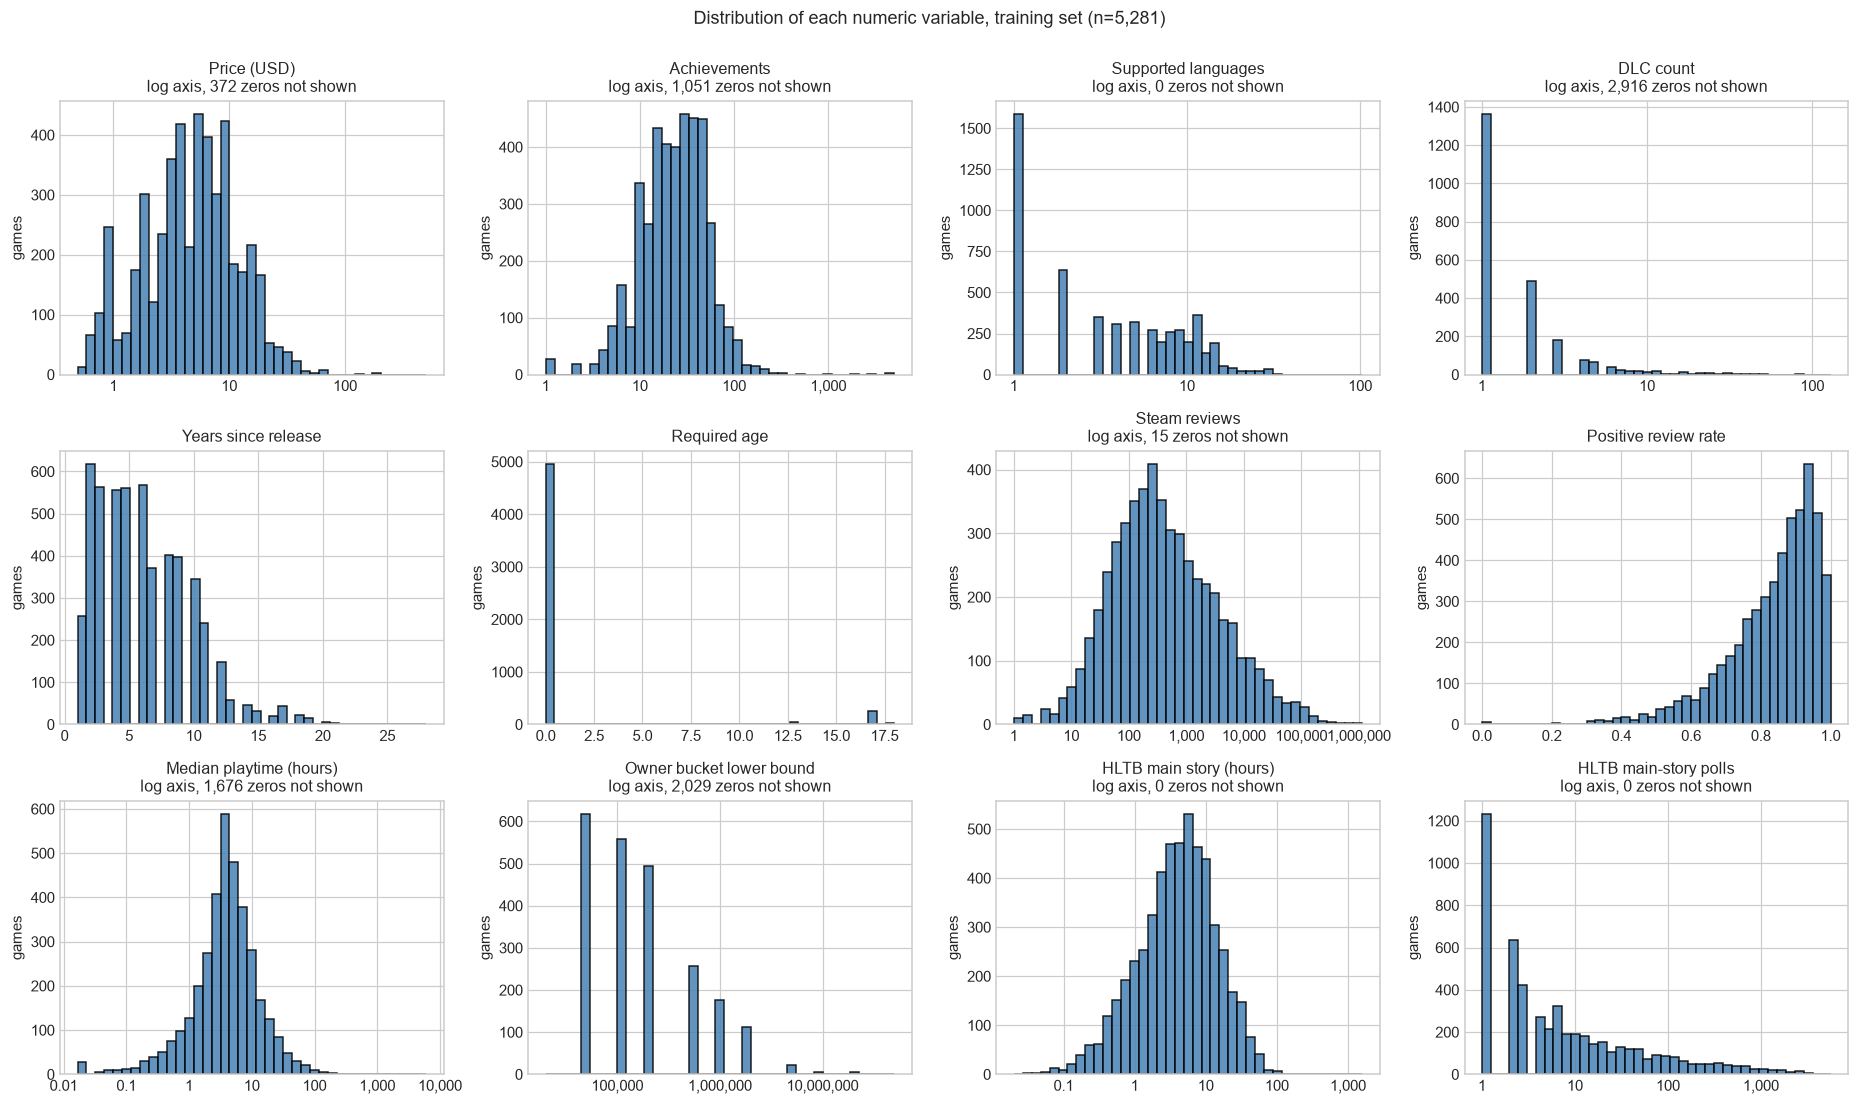

,pct_missing,pct_zero,median,skew
steam_price,0.00,7.04,4.39,24.25
steam_achievements,0.00,19.90,19.00,19.74
steam_language_count,0.00,0.00,4.00,6.09
steam_dlc_count,0.00,55.22,0.00,14.31
steam_years_since_release,0.00,0.00,6.00,0.91
steam_required_age,0.00,93.88,0.00,3.73
steam_review_count,0.00,0.28,333.00,19.41
steam_positive_rate,0.28,0.11,0.87,-1.56
steam_playtime_hours,0.00,31.74,2.28,59.31
steam_owners_lower,0.00,38.42,20000.00,26.56


In [3]:
OVERVIEW = [
    ("steam_price", "Price (USD)", True), ("steam_achievements", "Achievements", True),
    ("steam_language_count", "Supported languages", True), ("steam_dlc_count", "DLC count", True),
    ("steam_years_since_release", "Years since release", False), ("steam_required_age", "Required age", False),
    ("steam_review_count", "Steam reviews", True), ("steam_positive_rate", "Positive review rate", False),
    ("steam_playtime_hours", "Median playtime (hours)", True), ("steam_owners_lower", "Owner bucket lower bound", True),
    ("hltb_main_story", "HLTB main story (hours)", True), ("hltb_main_story_polled", "HLTB main-story polls", True),
]
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, (col, label, log) in zip(axes.ravel(), OVERVIEW):
    s = df[col].dropna().astype(float)
    if log:
        pos = s[s > 0]
        ax.hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 40), color="steelblue", edgecolor="black", alpha=0.85)
        ax.set_xscale("log"); ax.xaxis.set_major_formatter(READABLE); ax.xaxis.set_minor_formatter(mticker.NullFormatter())
        ax.set_title(f"{label}\nlog axis, {int((s <= 0).sum()):,} zeros not shown")
    else:
        ax.hist(s, bins=40, color="steelblue", edgecolor="black", alpha=0.85)
        ax.set_title(label)
    ax.set_ylabel("games")
fig.suptitle(f"Distribution of each numeric variable, training set (n={len(df):,})", y=1.0)
plt.tight_layout()
save_fig(fig, "01_q1_distributions_overview")
plt.show()

cols = [c for c, _, _ in OVERVIEW]
glance = pd.DataFrame({
    "pct_missing": df[cols].isna().mean() * 100,
    "pct_zero": (df[cols] == 0).mean() * 100,
    "median": df[cols].median(),
    "skew": df[cols].skew(),
})
glance.round(2)

### Interpretation: Every variable at a glance
**Author**: 
<!-- Give a first description of the training set from the overview figure and table: which variables are roughly symmetric, which are heavily right-skewed and need the log view, which have a large share of zeros, and which have bounded or bunched values (such as the positive rate or required age). Note anything that looks surprising and is followed up later in this notebook. -->

In [4]:
# What the columns are, grouped by what they describe
groups = {
    "Identity": ["steam_appid", "steam_name", "steam_release_date", "steam_year", "steam_years_since_release"],
    "Reception": ["steam_positive", "steam_negative", "steam_review_count", "steam_positive_rate",
                  "steam_metacritic_score", "steam_user_score", "steam_recommendations"],
    "Engagement": ["steam_median_playtime_forever", "steam_playtime_hours", "steam_average_playtime_forever",
                   "steam_peak_ccu", "steam_estimated_owners", "steam_owners_lower", "steam_owners_upper"],
    "Controllable": ["steam_price", "steam_achievements", "steam_dlc_count", "steam_language_count",
                     "steam_required_age", "steam_genres", "steam_categories", "steam_tags"],
    "HowLongToBeat": ["hltb_main_story", "hltb_main_story_polled", "hltb_main_plus_sides", "hltb_completionist"],
    "Join": ["title_key", "matched_hltb", "year_diff", "completion_ratio"],
}
rows = []
for group, cols in groups.items():
    for col in cols:
        if col in df.columns:
            rows.append({"group": group, "column": col, "dtype": str(df[col].dtype),
                         "n_unique": df[col].nunique(), "pct_null": round(df[col].isna().mean() * 100, 1)})
schema = pd.DataFrame(rows)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns\n")
schema

5,281 rows x 83 columns



,group,column,dtype,n_unique,pct_null
0,Identity,steam_appid,int64,5281,0.0
1,Identity,steam_name,object,5281,0.0
2,Identity,steam_release_date,object,2545,0.0
3,Identity,steam_year,int32,25,0.0
4,Identity,steam_years_since_release,int32,25,0.0
5,Reception,steam_positive,int64,2215,0.0
6,Reception,steam_negative,int64,1136,0.0
7,Reception,steam_review_count,int64,2353,0.0
8,Reception,steam_positive_rate,float64,4053,0.3
9,Reception,steam_metacritic_score,int64,51,0.0


**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** HowLongToBeat fields no longer have high null rates from matching: every row is matched. The remaining HLTB nulls are co-op, versus and side-content times that were never reported. Delete this note once revised.

The data can be split into 6 main types of fields. HLTB adds additional reception / engagement metrics that we will evaluate. Most of the columns from the steam dataset have little null values, but the HLTB fields have high null rates due to the matching criteria described in the previous notebook.

In [5]:
cols = ["steam_price", "steam_achievements", "steam_dlc_count", "steam_language_count",
        "steam_required_age", "steam_years_since_release", "steam_review_count",
        "steam_playtime_hours", "hltb_main_story"]
desc = df[cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["skew"] = df[cols].skew()
desc["pct_zero"] = (df[cols] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,pct_zero
steam_price,5281.0,6.46,10.31,0.00,1.99,4.39,8.74,19.94,29.99,500.00,24.25,7.04
steam_achievements,5281.0,36.66,237.59,0.00,6.00,19.00,35.00,70.00,135.00,5000.00,19.74,19.90
steam_dlc_count,5281.0,1.16,3.66,0.00,0.00,0.00,1.00,4.00,14.20,129.00,14.31,55.22
steam_language_count,5281.0,5.64,6.41,1.00,1.00,4.00,9.00,15.00,27.00,103.00,6.09,0.00
steam_required_age,5281.0,1.00,3.94,0.00,0.00,0.00,0.00,17.00,17.00,18.00,3.73,93.88
steam_years_since_release,5281.0,6.22,3.69,1.00,3.00,6.00,9.00,12.00,17.00,28.00,0.91,0.00
steam_review_count,5281.0,5600.52,33672.29,0.00,94.00,333.00,1735.00,20393.00,100285.60,1150098.00,19.41,0.28
steam_playtime_hours,5281.0,7.02,89.24,0.00,0.00,2.28,5.45,19.42,53.68,5994.57,59.31,31.74
hltb_main_story,5281.0,8.08,24.14,0.02,1.83,4.24,9.42,28.56,51.14,1591.65,53.77,0.00


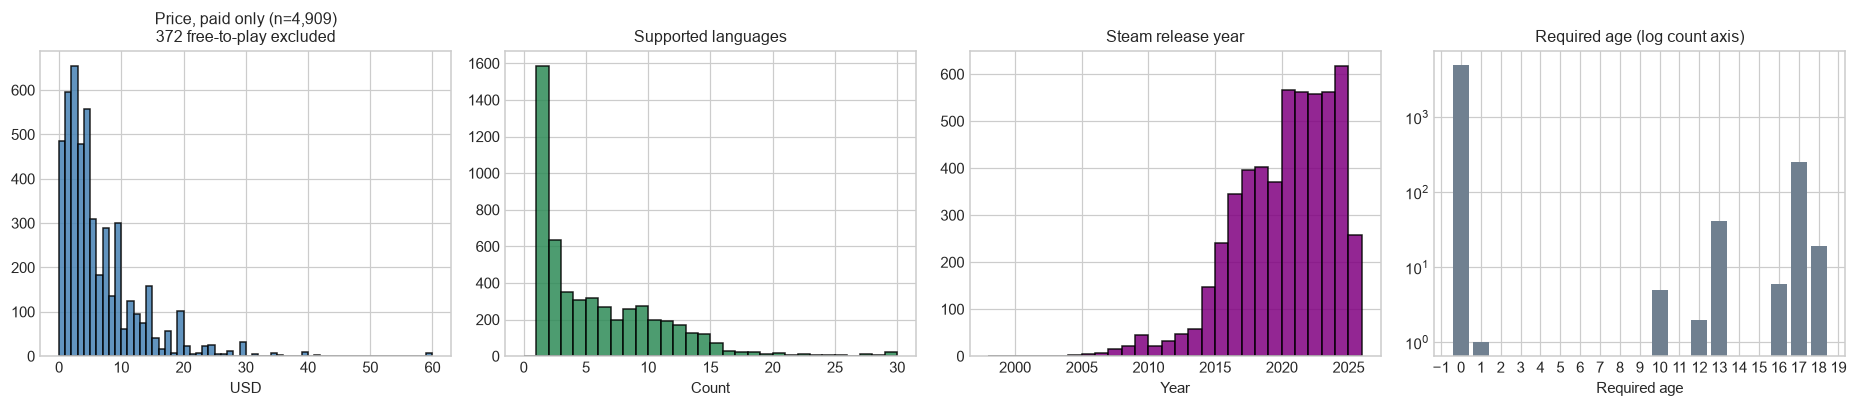

In [6]:
from matplotlib.ticker import MultipleLocator
# Variables that need no transformation
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))

paid = df.loc[df["steam_price"] > 0, "steam_price"]
axes[0].hist(paid, bins=60, range=(0, 60), color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_title(f"Price, paid only (n={len(paid):,})\n{(df['steam_price'] == 0).sum():,} free-to-play excluded")
axes[0].set_xlabel("USD")

axes[1].hist(df["steam_language_count"], bins=range(0, 31), color="seagreen", edgecolor="black", alpha=0.85)
axes[1].set_title("Supported languages")
axes[1].set_xlabel("Count")

yrs = df["steam_year"].dropna()
axes[2].hist(yrs, bins=range(int(yrs.min()), int(yrs.max()) + 2), color="purple", edgecolor="black", alpha=0.85)
axes[2].set_title("Steam release year")
axes[2].set_xlabel("Year")

age = df["steam_required_age"].value_counts().sort_index()
axes[3].bar(age.index, age.values, color="slategray")
axes[3].xaxis.set_major_locator(MultipleLocator(1))
axes[3].set_yscale("log")
axes[3].set_title("Required age (log count axis)")
axes[3].set_xlabel("Required age")

plt.tight_layout()
save_fig(fig, "01_q1_variables_untransformed")
plt.show()

**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** every figure here was regenerated on 5,281 scoped games. Check the release-year and age-requirement descriptions against the new figure. Delete this note once revised.

Price for paid games follows a downward trend, with a long right tail of games > $20. This indicates that the majority of paid games released are targeted fairly affordably, though this does not mean it has good total revenue.

Supported languages peaks at 1, with a long right tail up to 30. Most games are made in and targeting one main language.

The number of games has been increasing year over year, with noticeable increases in 2024 and 2025 over the previous years. The data stopped partly through 2026, hence the small bar. 

Age requirement for games varies, but generally clusters around regulatory requirements. Key numbers are 17/18 for adult games and 13 for semi-violent games.

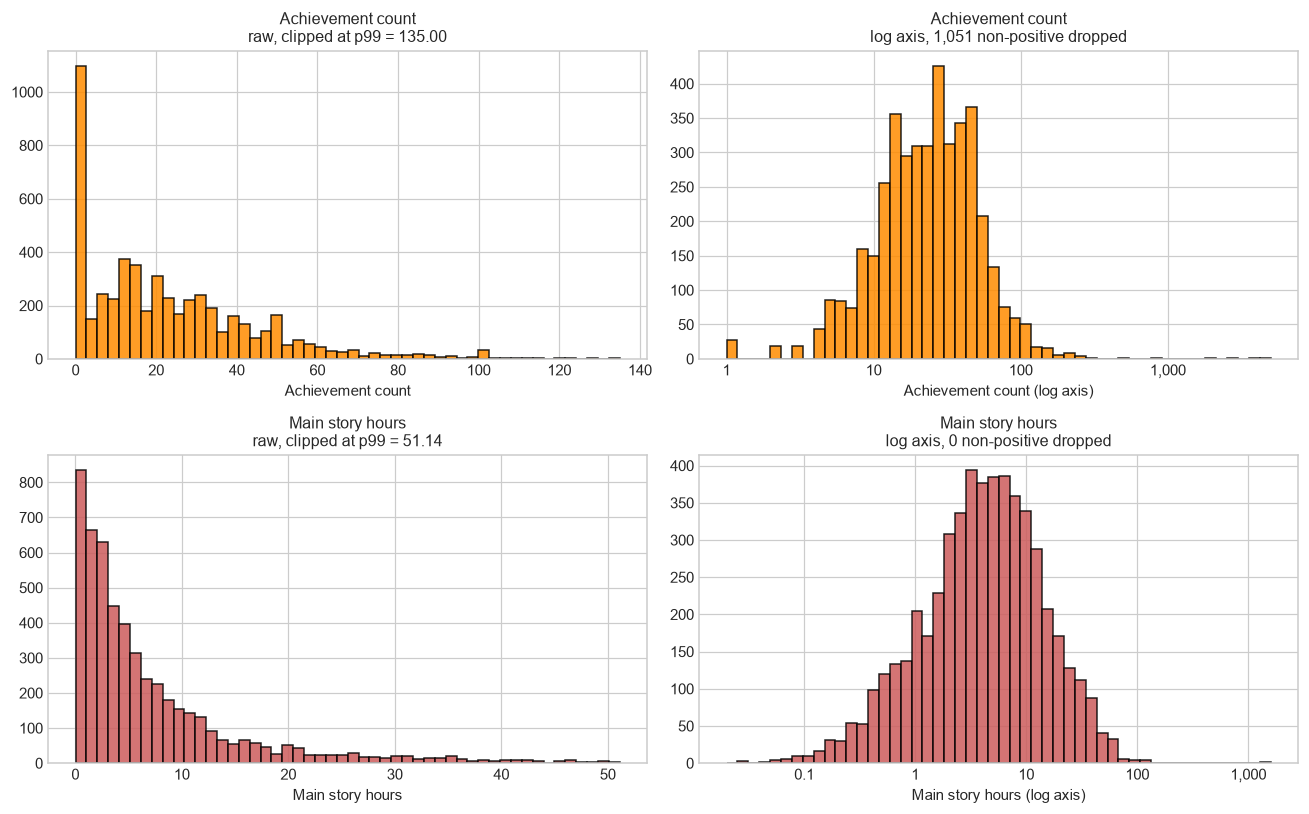

In [7]:
# Heavy-tailed variables, shown raw and then on a log axis
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
raw_vs_log(axes[0], df["steam_achievements"], "Achievement count", "darkorange")
raw_vs_log(axes[1], df["hltb_main_story"], "Main story hours", "indianred")
plt.tight_layout()
save_fig(fig, "01_q1_heavy_tailed_raw_vs_log")
plt.show()

**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** games with 0 achievements are now 19.9% of the sample, not the majority. Check the HLTB hours description against the regenerated figure. Delete this note once revised.

The number of achievements follows a somewhat log-normal distribution, though it has long right tail. The majority of games have 0 achievements. 

The expected number of hours from HLTB also follows a somewhat log-normal distribution. It is slightly less symmetrical, with more games less than the mean than more.

In [8]:
def top_tokens(series, n=12):
    tok = series.fillna("").str.split(",").explode().str.strip()
    tok = tok[tok.ne("")]
    out = tok.value_counts().head(n).to_frame("games")
    out["pct_of_rows"] = (out["games"] / len(series) * 100).round(1)
    return out

for name in ["steam_genres", "steam_categories"]:
    print(f"--- Top {name} ---")
    print(top_tokens(df[name]).to_string())
    print()

--- Top steam_genres ---
                       games  pct_of_rows
steam_genres                             
Adventure               3570         67.6
Indie                   3558         67.4
Casual                  1620         30.7
Action                  1485         28.1
RPG                     1376         26.1
Simulation               907         17.2
Strategy                 582         11.0
Free To Play             234          4.4
Early Access              57          1.1
Sports                    46          0.9
Racing                    25          0.5
Massively Multiplayer     12          0.2

--- Top steam_categories ---
                            games  pct_of_rows
steam_categories                              
Single-player                5281        100.0
Family Sharing               4902         92.8
Steam Achievements           3965         75.1
Steam Cloud                  2707         51.3
Full controller support      2061         39.0
Steam Trading Cards         

### Interpretation: What the data looks like
**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** the point about most rows being unmatched no longer applies: every row is matched, and only 19.9% have no achievements. The interpretation needs rewriting for the scoped sample. Delete this note once revised.

<!-- Describe the shape of the training set and the distribution of the main variables. Cover which variables are heavily skewed or zero-inflated, whether the log view changes what you conclude from the raw view, which variables will need a transformation before modelling, how concentrated the release years are, and which genres and categories dominate the catalogue. -->
Overall, the data presents some key data quality issues. The most important one is that due to the matching between datasets, most rows did not get matched as they are likely to be simple games that did not get much popularity. This extends further into the characteristics of these games, as a noticeable amount of them have no achievements (a controllable variable) and only support one language (another controllable variable).


## 2. Missingness and data anomalies
*Code: Generated by AI Assistant*

*Written by AI Assistant*: a zero in this data can mean three different things, so they are separated below: a sentinel for absent, an unobserved outcome, and a genuine value such as a free-to-play price. Three anomalies follow: software sold on Steam that is not a game, implausible playtimes, and duplicate or inconsistent keys.

### Missingness at a glance
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the left panel shows the share of games with a true null in each column that has any. The right panel shows the zeros that stand for a missing value rather than a real zero (the first three rows of the table below), so the two kinds of missingness can be compared on one scale. Free-text and URL columns are left out of the left panel.

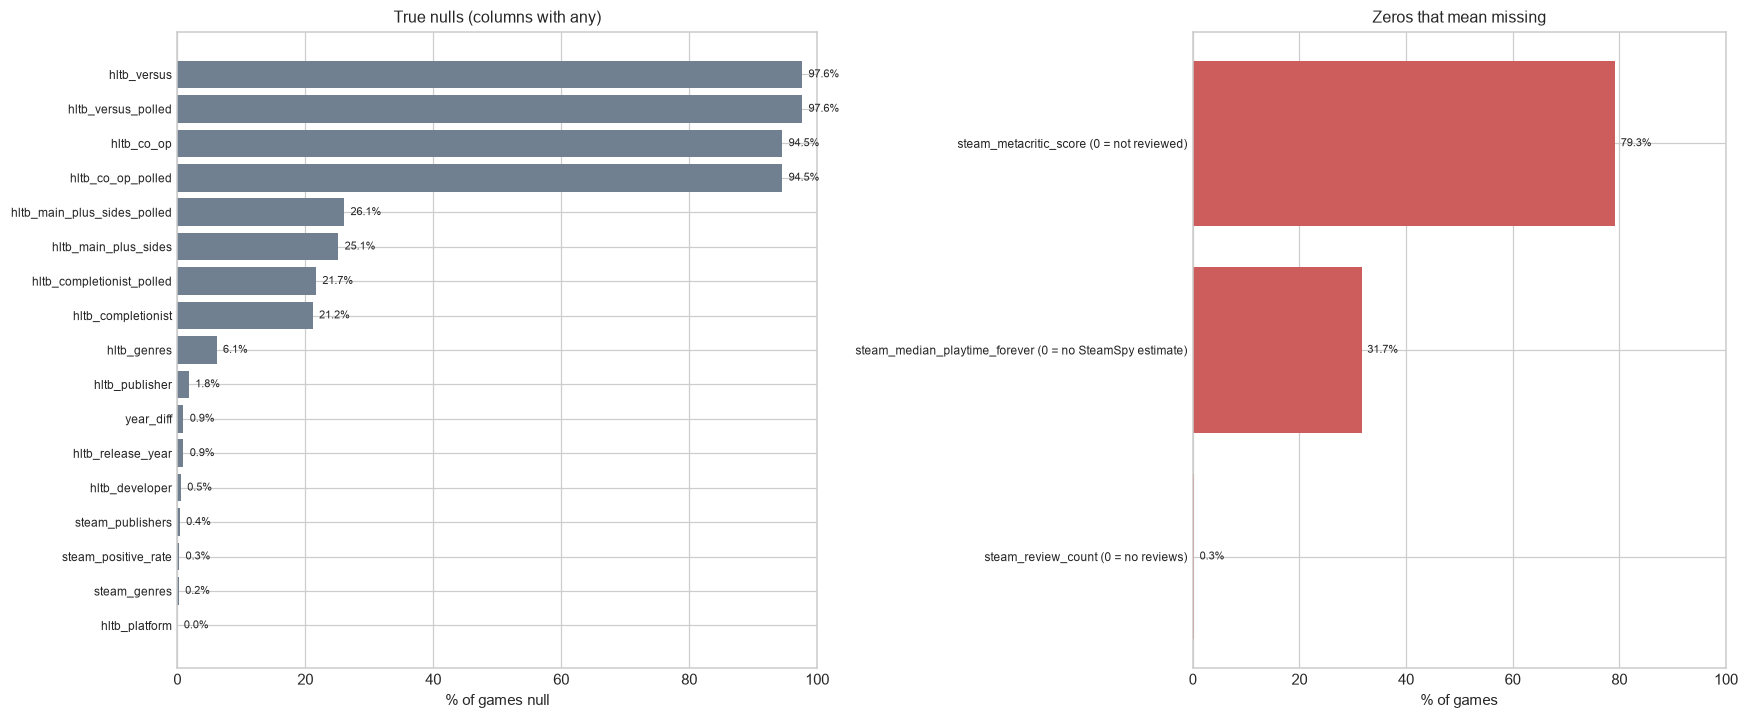

In [9]:
SKIP = ("steam_movies", "steam_screenshots", "steam_header_image", "steam_about_the_game", "steam_notes",
        "steam_reviews", "steam_metacritic_url", "steam_score_rank", "steam_website", "steam_support_url", "steam_support_email")
nulls = (df.drop(columns=[c for c in SKIP if c in df]).isna().mean() * 100)[lambda s: s > 0].sort_values()
zero_missing = pd.Series({
    "steam_metacritic_score (0 = not reviewed)": (df["steam_metacritic_score"] == 0).mean() * 100,
    "steam_median_playtime_forever (0 = no SteamSpy estimate)": (df["steam_median_playtime_forever"] == 0).mean() * 100,
    "steam_review_count (0 = no reviews)": (df["steam_review_count"] == 0).mean() * 100,
}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, max(3.5, 0.32 * len(nulls) + 1.2)), gridspec_kw={"width_ratios": [1.2, 1]})
axes[0].barh(nulls.index, nulls.values, color="slategray")
axes[0].set_xlim(0, 100); axes[0].set_xlabel("% of games null")
axes[0].set_title("True nulls (columns with any)")
axes[0].tick_params(axis="y", labelsize=8)
axes[1].barh(zero_missing.index, zero_missing.values, color="indianred")
axes[1].set_xlim(0, 100); axes[1].set_xlabel("% of games")
axes[1].set_title("Zeros that mean missing")
axes[1].tick_params(axis="y", labelsize=8)
for ax, s in [(axes[0], nulls), (axes[1], zero_missing)]:
    for y, v in enumerate(s.values):
        ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=7)
plt.tight_layout()
save_fig(fig, "01_q2_missingness")
plt.show()

### Interpretation: Missingness at a glance
**Author**: 
<!-- Describe where data is missing: which columns have true nulls and why (for example HowLongToBeat times that players never reported), which variables use zero to mean missing, and how large each share is. Say which missing values matter for the candidate success metrics in section 3 and which only affect columns that are not used. -->

In [10]:
# Three different kinds of absence, which pandas shows identically as 0 or NaN
sentinel = pd.DataFrame([
    {"column": "steam_metacritic_score", "kind": "0 means absent", "n": int((df["steam_metacritic_score"] == 0).sum())},
    {"column": "steam_median_playtime_forever", "kind": "0 means SteamSpy could not estimate", "n": int((df["steam_median_playtime_forever"] == 0).sum())},
    {"column": "steam_review_count", "kind": "0 means outcome never observed", "n": int((df["steam_review_count"] == 0).sum())},
    {"column": "steam_price", "kind": "0 is a real value, free-to-play", "n": int((df["steam_price"] == 0).sum())},
    {"column": "steam_achievements", "kind": "0 is a real value, no achievements", "n": int((df["steam_achievements"] == 0).sum())},
])
sentinel["pct"] = (sentinel["n"] / len(df) * 100).round(1)
print(sentinel.to_string(index=False))
print("\nColumns with true nulls:")
print(df.isna().sum()[lambda s: s > 0].sort_values(ascending=False).head(15).to_string())

                       column                                kind    n  pct
       steam_metacritic_score                      0 means absent 4186 79.3
steam_median_playtime_forever 0 means SteamSpy could not estimate 1676 31.7
           steam_review_count      0 means outcome never observed   15  0.3
                  steam_price     0 is a real value, free-to-play  372  7.0
           steam_achievements  0 is a real value, no achievements 1051 19.9

Columns with true nulls:
steam_movies                   5281
steam_score_rank               5279
hltb_versus                    5156
hltb_versus_polled             5156
hltb_co_op                     4992
hltb_co_op_polled              4992
steam_metacritic_url           4186
steam_notes                    3714
steam_reviews                  3482
steam_support_url              2001
steam_website                  1722
hltb_main_plus_sides_polled    1376
hltb_main_plus_sides           1328
hltb_completionist_polled      1144
hltb_completio

**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** the nulls are no longer unmatched HLTB rows. They are HLTB co-op, versus and side-content times that were never reported. Delete this note once revised.

Of the null values, most are HLTB fields (no match). Price and number of achievements have a true 0, meaning a free game or having no achievements.

In [11]:
# Anomaly 1: rows that are software rather than games
# The genre list (NON_GAME_GENRES) lives in src/is630/features.py, shared with notebook 07
from is630.features import is_software
df["steam_is_software"] = is_software(df["steam_genres"])

print(f"rows carrying a non-game genre: {df['steam_is_software'].sum():,} ({df['steam_is_software'].mean() * 100:.1f}%)")
print(f"  among the 100 highest playtimes: {df.nlargest(100, 'steam_playtime_hours')['steam_is_software'].sum()}")
show = df[df["steam_is_software"]].nlargest(8, "steam_playtime_hours")[
    ["steam_name", "steam_playtime_hours", "steam_review_count", "steam_genres"]].copy()
show["steam_name"] = ascii_names(show["steam_name"])
show["steam_genres"] = ascii_names(show["steam_genres"])
show.round(1)

rows carrying a non-game genre: 0 (0.0%)
  among the 100 highest playtimes: 0


,steam_name,steam_playtime_hours,steam_review_count,steam_genres


**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** no software rows remain in the scoped sample, so the usage-pattern argument has no data behind it here. Delete this note once revised.

While Steam is a primarily game platform, it also has different software that are productivity-focused. The usage patterns differ, with software likely to have less users but longer usage time (for freelancers, small businesses, etc). 0% of the dataset is not a game, and 0 of them are part of the top 100 in median playtime, indicating confirmation of this usage pattern. This also extends to the HLTB match, as software is by its nature unlikely to appear there.

In [12]:
# Anomaly 2: implausible playtime
print(f"playtime > 1,000 h : {(df['steam_playtime_hours'] > 1000).sum():,} games")
print(f"playtime > 8,760 h : {(df['steam_playtime_hours'] > 8760).sum():,} games (more than a year of wall-clock)")
print(f"playtime == 0      : {(df['steam_playtime_hours'] == 0).sum():,} games ({(df['steam_playtime_hours'] == 0).mean() * 100:.1f}%)")

extreme = df.nlargest(10, "steam_playtime_hours")[
    ["steam_name", "steam_playtime_hours", "steam_review_count", "steam_owners_lower", "steam_price", "steam_genres"]].copy()
extreme["steam_name"] = ascii_names(extreme["steam_name"])
extreme["steam_genres"] = ascii_names(extreme["steam_genres"]).str.slice(0, 38)
extreme.round(1)

playtime > 1,000 h : 3 games
playtime > 8,760 h : 0 games (more than a year of wall-clock)
playtime == 0      : 1,676 games (31.7%)


,steam_name,steam_playtime_hours,steam_review_count,steam_owners_lower,steam_price,steam_genres
1768,Letters From a Rainy Day -Oceans and Lace-,5994.6,897,20000,11.9,Adventure
1073,GINKA,1622.2,2604,100000,13.8,"Adventure,Casual"
604,Lay a Beauty to Rest: The Darkness Peach Bloss...,1471.6,6464,200000,6.0,"Adventure,Casual,Indie,RPG"
2912,Nurse Love Syndrome,618.4,262,20000,16.0,Adventure
2067,Blackberry Honey,564.8,627,0,7.8,"Adventure,Indie"
2564,Hero Tale,266.5,360,50000,3.6,"Indie,RPG,Strategy"
1835,Disgaea 4 Complete+,222.0,822,50000,14.0,"RPG,Strategy"
1262,HENPRI,203.8,1894,20000,17.5,"Adventure,Casual"
3964,Facehand,185.0,93,0,3.5,Strategy
2925,SaGa Frontier 2 Remastered,175.2,259,0,21.0,RPG


**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** 31.7% is not most games, and the outlier is no longer above a year of wall-clock time. Delete this note once revised.

In terms of outliers by median playtime, we identified 3 games with more than 1000 median hours (or about 42 straight days), and one game with a clear outlier at 5,995 hours. Most of these games are niche, with a low number of players leading to the median being pulled up by anomalous users. Most games (31.7%) have no median playtime, part of the long right tail of unpopular games discovered earlier.

In [13]:
# Anomaly 3: duplicate and near-duplicate titles, and date problems
print(f"duplicate steam_appid: {df['steam_appid'].duplicated().sum():,}")
print(f"duplicate normalised titles: {df['title_key'].duplicated().sum():,}  (stage 00 already reduced these)")
print(f"missing Steam release year: {df['steam_year'].isna().sum():,}")
print(f"release year beyond the snapshot year ({config.SNAPSHOT_YEAR}): {(df['steam_year'] > config.SNAPSHOT_YEAR).sum():,}")
print(f"hltb_main_story <= 0: {(df['hltb_main_story'] <= 0).sum():,}")
print(f"match found by the edition fallback (match_pass 2): {int((df['match_pass'] == 2).sum()):,}")
print("\nSteam year minus HowLongToBeat year:")
print(df["year_diff"].describe(percentiles=[0.05, 0.5, 0.95]).round(2).to_string())

duplicate steam_appid: 0
duplicate normalised titles: 0  (stage 00 already reduced these)
missing Steam release year: 0
release year beyond the snapshot year (2026): 0
hltb_main_story <= 0: 0
match found by the edition fallback (match_pass 2): 102

Steam year minus HowLongToBeat year:
count    5231.00
mean        0.96
std         3.63
min        -6.00
5%          0.00
50%         0.00
95%         5.00
max        43.00


**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** the mean Steam year minus HowLongToBeat year is +0.96, so Steam lists games later than HowLongToBeat does, not earlier. Check the direction in the last sentence. Delete this note once revised.

No other obvious data quality issues in terms of duplicates and impossible data. Steam year and HLTB year differs slightly, but generally HLTB lists games as more recent than they are on Steam.

## 3. What are our prospective target variables?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this section is the evidence for AQ1. Six candidates are compared on coverage, zero inflation, skew and outliers, including the completion ratio. Each heavy-tailed candidate is shown untransformed and then on a log scale.

Sections 3 to 8 measure every candidate on the same properties, and section 8 puts them in one table: how many games it is defined for (section 3), how it is distributed and how many zeros it has (section 3), whether it depends on game length (end of section 3), whether the candidates agree on which games are top (section 4), whether it grows with a game's age (section 5), how it correlates with audience size and with the other candidates (section 6), and how precisely it is measured (section 7).

In [14]:
candidates = {
    "steam_positive_rate": df["steam_positive_rate"],
    "steam_review_count": df["steam_review_count"].astype(float),
    "steam_metacritic_score": df.loc[df["steam_metacritic_score"] > 0, "steam_metacritic_score"].astype(float),
    "steam_playtime_hours": df["steam_playtime_hours"],
    "steam_owners_lower": df["steam_owners_lower"],
    "completion_ratio": df["completion_ratio"],
}
rows = []
for name, s in candidates.items():
    rows.append({
        "target": name,
        "n_defined": int(s.notna().sum()),
        "pct_of_train": round(s.notna().sum() / len(df) * 100, 1),
        "pct_zero": round(float((s == 0).mean() * 100), 1),
        "median": round(float(s.median()), 3),
        "mean": round(float(s.mean()), 3),
        "skew": round(float(s.skew()), 2),
        "p99": round(float(s.quantile(0.99)), 2),
        "max": round(float(s.max()), 2),
    })
pd.DataFrame(rows).set_index("target")

,n_defined,pct_of_train,pct_zero,median,mean,skew,p99,max
target,,,,,,,,
steam_positive_rate,5266,99.7,0.1,0.870,0.834,-1.56,1.00,1.00
steam_review_count,5281,100.0,0.3,333.000,5600.515,19.41,100285.60,1150098.00
steam_metacritic_score,1095,20.7,0.0,78.000,76.526,-0.72,94.00,96.00
steam_playtime_hours,5281,100.0,31.7,2.283,7.025,59.31,53.68,5994.57
steam_owners_lower,5281,100.0,38.4,20000.000,210437.417,26.56,2000000.00,50000000.00
completion_ratio,5281,100.0,31.7,0.423,1.225,43.37,10.39,592.93


**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** the completion ratio is now defined for every game (5,281), with 3,605 non-zero, so it is no longer the smallest sample. The "only" framing no longer holds. Delete this note once revised.

We evaluate 6 different metrics of what a "popular" game can be. Review count, playtime hours, and number of owners has the most number of data points at 5281. However, these may not translate to good overall sales as they only factor in the number of people it has reached and not reception (which is admittedly somewhat correlated), and playtime hours and number of owners has many zero values. The positive review rate has 5266 data points, but each is an aggregation of the proportion per game already. Metacritic score is the most selective, with only 1095 games appearing on metacritic. Completion ratio which we propose has only 5281 games. Apart from the positive rate and metacritic scores (which are proportions), the rest have high skew with the long right tail.

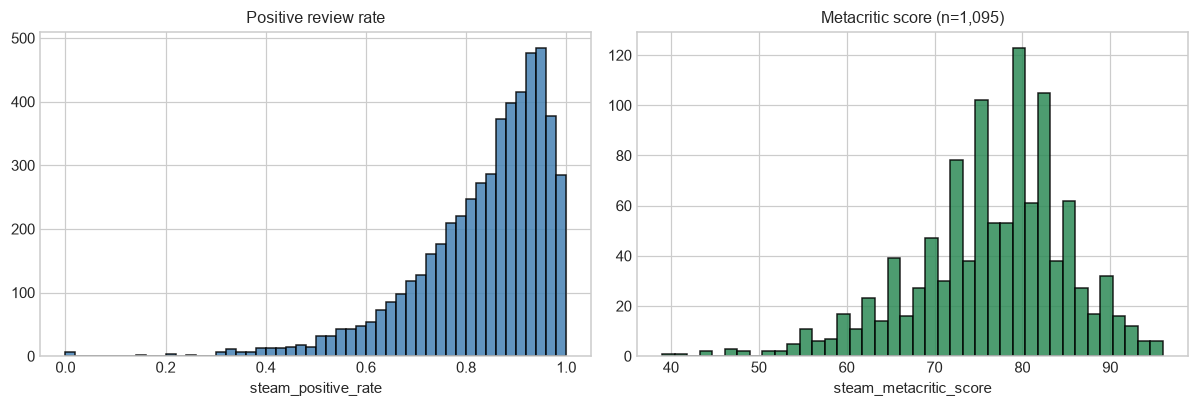

In [15]:
# Candidate targets that need no transformation
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["steam_positive_rate"].dropna(), bins=50, color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_title("Positive review rate")
axes[0].set_xlabel("steam_positive_rate")
mc = df.loc[df["steam_metacritic_score"] > 0, "steam_metacritic_score"]
axes[1].hist(mc, bins=40, color="seagreen", edgecolor="black", alpha=0.85)
axes[1].set_title(f"Metacritic score (n={len(mc):,})")
axes[1].set_xlabel("steam_metacritic_score")
plt.tight_layout()
save_fig(fig, "01_q3_targets_untransformed")
plt.show()

**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** with almost no low-review games left in scope, check whether the peaks at 0 and 0.5 in the positive rate still appear in the regenerated figure. Delete this note once revised.

Looking at the 2 review rate metrics, positive review rate has clear peaks at 0, 0.5 and 1.0. This is consistent with low review games having only a few reviews that are positive and negative. Overall, the positive review rate leans positive (majority > 0.5).

Metacritic score has a main spike at 80, close to the mean of around 75. It follows a somewhat normal distribution, but with more values on the left of the mean than the right. Metacritic score is a cleaner metric but has much lower sample size.

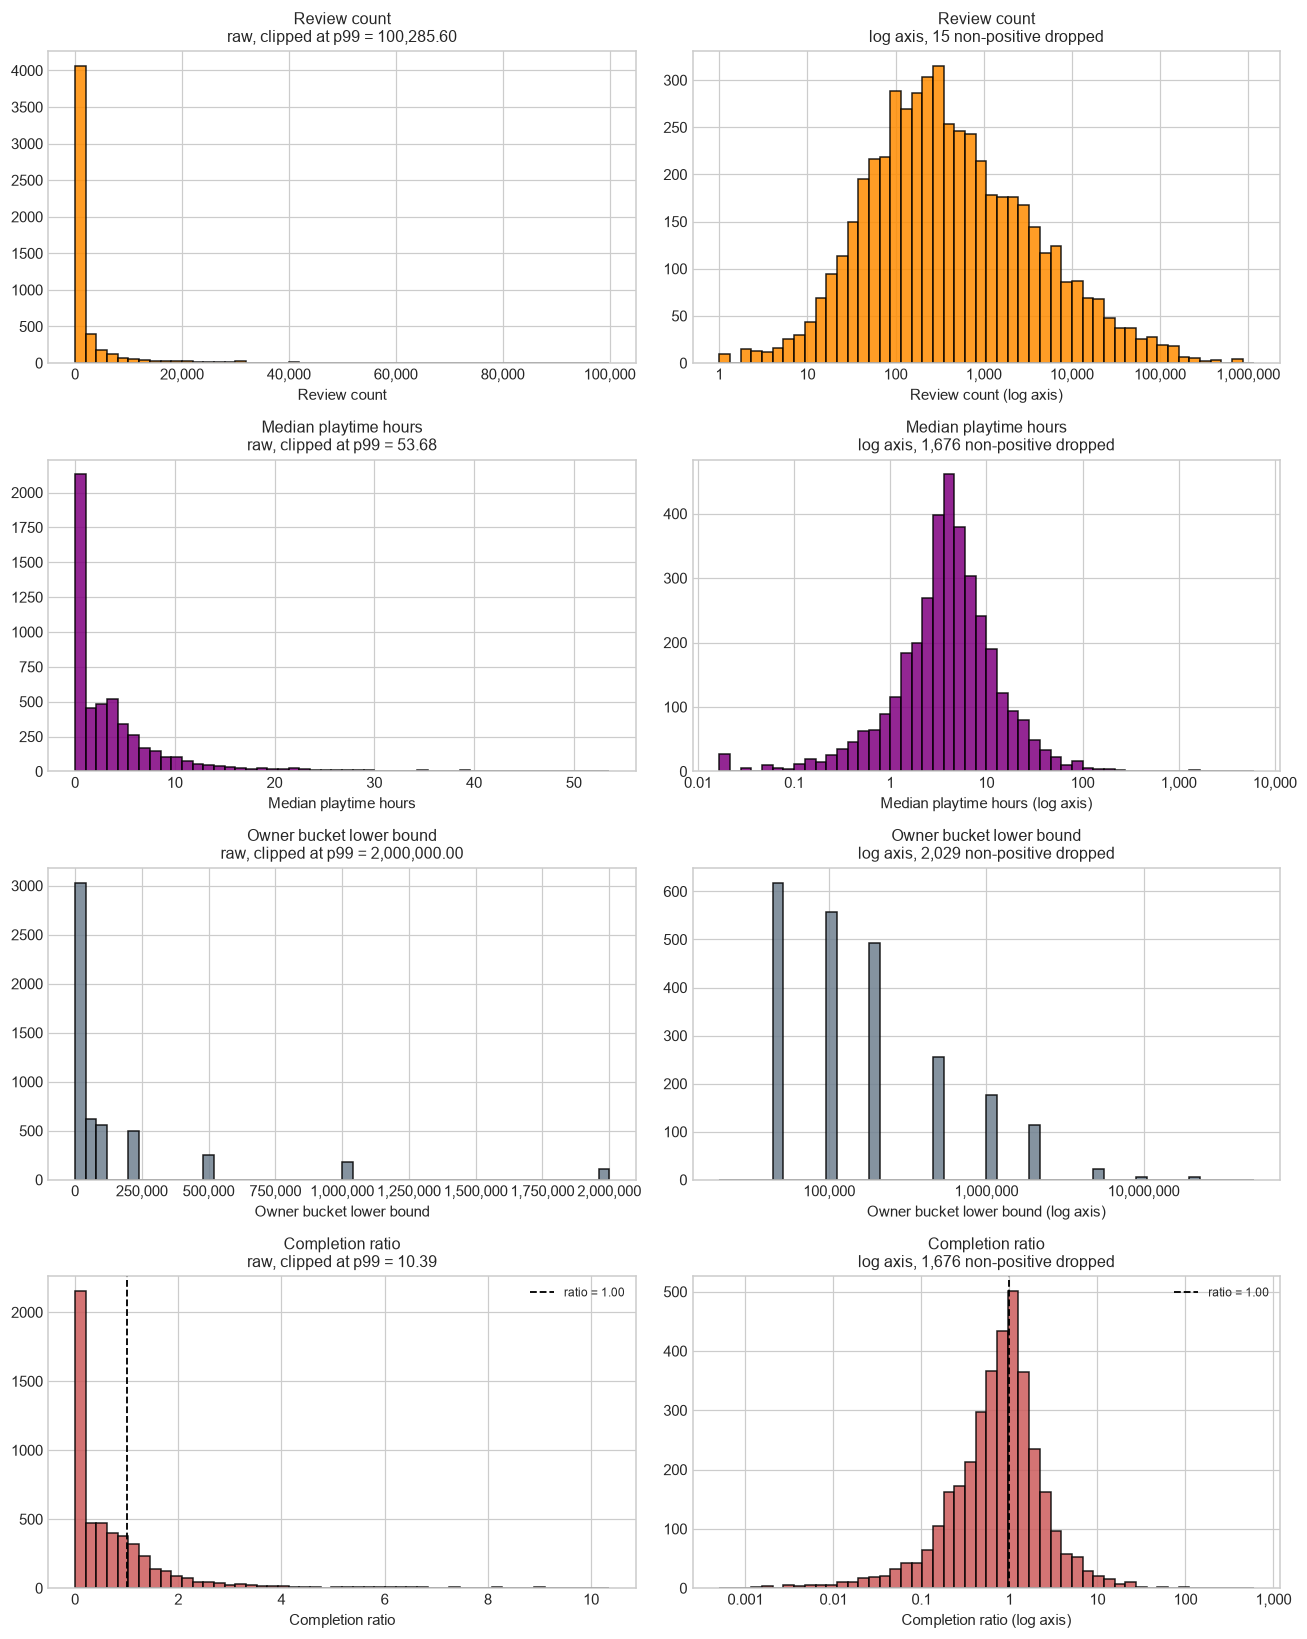

In [16]:
# Heavy-tailed candidate targets, raw on the left and on a log axis on the right
fig, axes = plt.subplots(4, 2, figsize=(12, 15))
raw_vs_log(axes[0], df["steam_review_count"].astype(float), "Review count", "darkorange")
raw_vs_log(axes[1], df["steam_playtime_hours"], "Median playtime hours", "purple")
raw_vs_log(axes[2], df["steam_owners_lower"], "Owner bucket lower bound", "slategray")
raw_vs_log(axes[3], df["completion_ratio"], "Completion ratio", "indianred")
axes[3][1].axvline(1, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[3][1].legend(fontsize=8)
axes[3][0].axvline(1, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[3][0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_q3_targets_raw_vs_log")
plt.show()

**Author**: Lee Sin Yang

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** the median game now has 333 reviews, not 0 to 50. Check the review, playtime and owner descriptions against the regenerated figure. Delete this note once revised.

The 4 other metrics are heavily 0-spiked with long right tails, thus we log transform them and filter the 0s to better see the differences.

Most games have around 0-50 reviews, with a gradual decline in log-scale afterwards. Median playtime hours peaks around 5 hours, following a somewhat lognormal distribution. The owner bucket lower bound is actually a categorical variable, as they are in buckets. There are only a small number (<1000) games with more than 1M owners. To account for games having different targeted hours (e.g. an indie game might have low hours, while a big AAA game might have high hours), we propose completion ratio as the median steam hours divided by the expected number of hours to complete. Completion ratio follows the most lognormal distribution, centred around the 1.0 ratio. 

In [17]:
# The completion ratio in detail: zero inflation, tail, and its two components
cr_all = df["completion_ratio"]
print(f"games                       : {len(df):,}")
print(f"  completion ratio is zero  : {(cr_all == 0).sum():,} ({(cr_all == 0).mean() * 100:.1f}%)  <- SteamSpy playtime of 0")
print(f"  ratio in (0, 1]           : {((cr_all > 0) & (cr_all <= 1)).sum():,}")
print(f"  ratio > 1                 : {(cr_all > 1).sum():,}")
print(f"  ratio > 5                 : {(cr_all > 5).sum():,}")
print("\nquantiles of the positive ratio:")
print(cr_all[cr_all > 0].quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3).to_string())

games                       : 5,281
  completion ratio is zero  : 1,676 (31.7%)  <- SteamSpy playtime of 0
  ratio in (0, 1]           : 2,126
  ratio > 1                 : 1,479
  ratio > 5                 : 154

quantiles of the positive ratio:
0.01     0.012
0.25     0.386
0.50     0.822
0.75     1.401
0.95     4.259
0.99    12.837


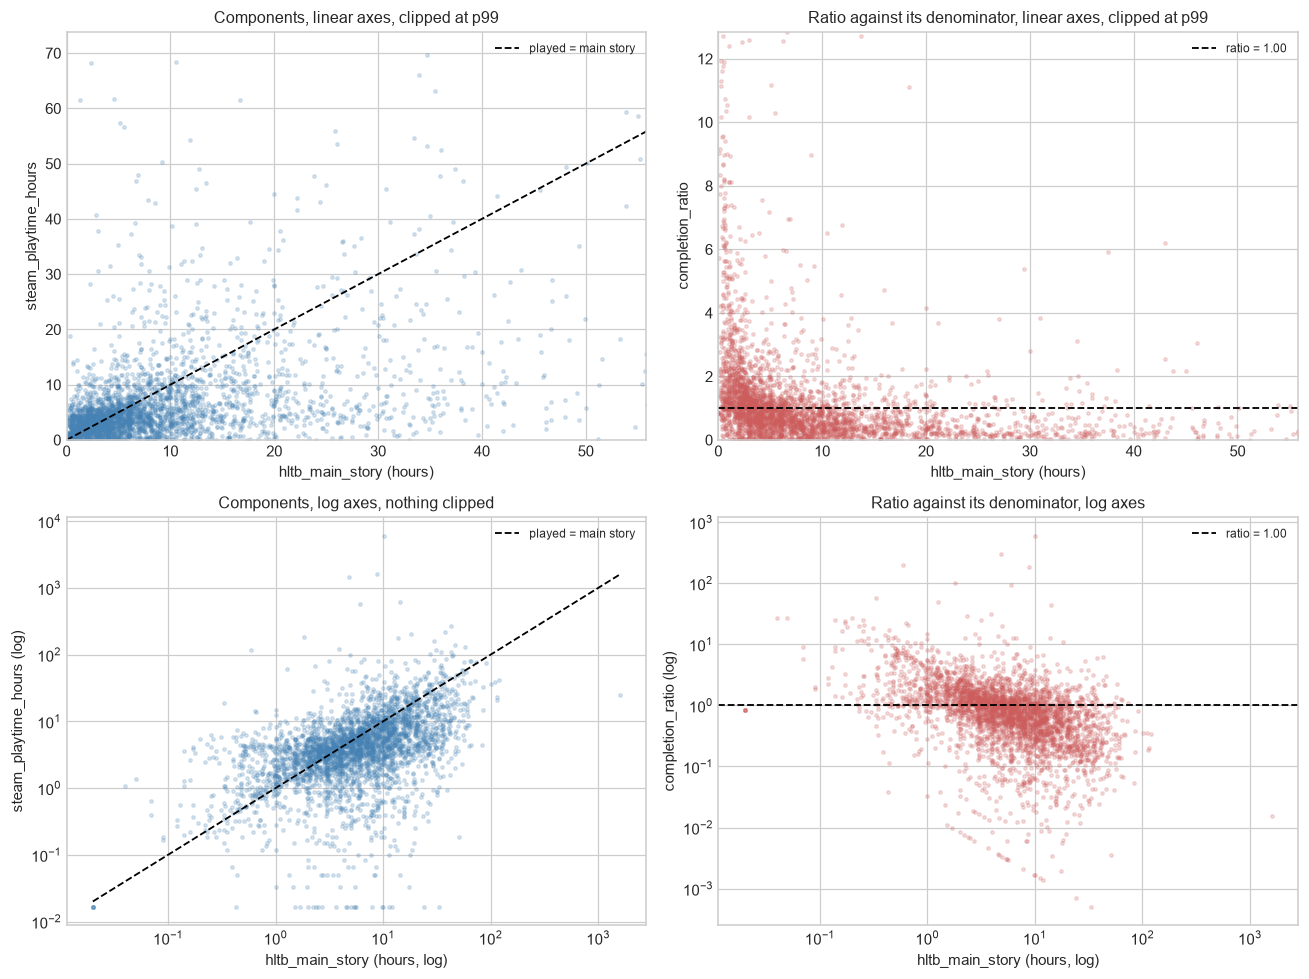

The right-hand panels divide by the quantity on their x axis, so a negative slope
appears from arithmetic alone. The left-hand panels show the same data without that.


In [18]:
# The two components, and the ratio, on linear axes and then on log axes
pos = df[(df["completion_ratio"] > 0) & (df["hltb_main_story"] > 0)]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Row 0: linear axes, clipped so the bulk is visible
xc, yc = pos["hltb_main_story"].quantile(0.99), pos["steam_playtime_hours"].quantile(0.99)
axes[0, 0].scatter(pos["hltb_main_story"], pos["steam_playtime_hours"], s=5, alpha=0.2, color="steelblue")
axes[0, 0].plot([0, xc], [0, xc], color="black", linestyle="--", linewidth=1.2, label="played = main story")
axes[0, 0].set_xlim(0, xc); axes[0, 0].set_ylim(0, yc)
axes[0, 0].set_xlabel("hltb_main_story (hours)"); axes[0, 0].set_ylabel("steam_playtime_hours")
axes[0, 0].set_title("Components, linear axes, clipped at p99")
axes[0, 0].legend(fontsize=8)

axes[0, 1].scatter(pos["hltb_main_story"], pos["completion_ratio"], s=5, alpha=0.2, color="indianred")
axes[0, 1].axhline(1.0, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[0, 1].set_xlim(0, xc); axes[0, 1].set_ylim(0, pos["completion_ratio"].quantile(0.99))
axes[0, 1].set_xlabel("hltb_main_story (hours)"); axes[0, 1].set_ylabel("completion_ratio")
axes[0, 1].set_title("Ratio against its denominator, linear axes, clipped at p99")
axes[0, 1].legend(fontsize=8)

# Row 1: the same two plots on log axes
axes[1, 0].scatter(pos["hltb_main_story"], pos["steam_playtime_hours"], s=5, alpha=0.2, color="steelblue")
lims = [pos["hltb_main_story"].min(), pos["hltb_main_story"].max()]
axes[1, 0].plot(lims, lims, color="black", linestyle="--", linewidth=1.2, label="played = main story")
axes[1, 0].set_xscale("log"); axes[1, 0].set_yscale("log")
axes[1, 0].set_xlabel("hltb_main_story (hours, log)"); axes[1, 0].set_ylabel("steam_playtime_hours (log)")
axes[1, 0].set_title("Components, log axes, nothing clipped")
axes[1, 0].legend(fontsize=8)

axes[1, 1].scatter(pos["hltb_main_story"], pos["completion_ratio"], s=5, alpha=0.2, color="indianred")
axes[1, 1].axhline(1.0, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[1, 1].set_xscale("log"); axes[1, 1].set_yscale("log")
axes[1, 1].set_xlabel("hltb_main_story (hours, log)"); axes[1, 1].set_ylabel("completion_ratio (log)")
axes[1, 1].set_title("Ratio against its denominator, log axes")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
save_fig(fig, "01_q3_completion_ratio_raw_vs_log")
plt.show()
print("The right-hand panels divide by the quantity on their x axis, so a negative slope")
print("appears from arithmetic alone. The left-hand panels show the same data without that.")

**Author**: Lee Sin Yang

The scatter plot of steam playtime hours against HLTB hours (top left) shows the distribution of games, which is not a clean diagonal line. Instead, the main cluster is in <10 hours on both, with more sporadic points as both values increase. When turning this into the completion ratio, most of the high completion ratios are due to low HLTB hours (i.e., low hours to complete hence a high ratio).

By log transforming the axes, we can see a better trend. Most values cluster in the center, roughly along the diagonal line of a 1.0 ratio. After creating the ratio on a log scale, the values are all fairly clustered and centered around 1.0. 

### Does the completion ratio remove the dependence on game length?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: median playtime alone favours long games, because a longer game takes longer to finish. The completion ratio divides playtime by the HowLongToBeat main-story time to remove that. If playtime grew in proportion to game length, the ratio would be flat across lengths. The cell checks this two ways, on games with a usable (non-zero) ratio:

- Median playtime and median ratio by main-story length quintile, with Spearman correlations against main-story hours.
- The slope of log playtime on log main-story hours. A slope of 1 means playtime grows in proportion to length, so the ratio is unaffected by length. A slope of 0 means playtime ignores length, so the ratio falls one for one as length rises.

The same numbers are repeated for the completion-model sample of notebook 02 (at least 50 reviews and 5 HowLongToBeat polls), the games AQ2 models. As noted under the scatter plots above, dividing by main-story hours builds some negative relationship with main-story hours into the ratio by construction.

,games,median_main_story,median_playtime,median_ratio
hltb_main_story,,,,
"(0.019, 2.17]",722,1.13,2.03,1.69
"(2.17, 4.23]",722,3.08,3.20,1.04
"(4.23, 7.45]",721,5.72,4.50,0.78
"(7.45, 13.754]",719,10.00,5.72,0.56
"(13.754, 1591.65]",721,22.84,9.00,0.38


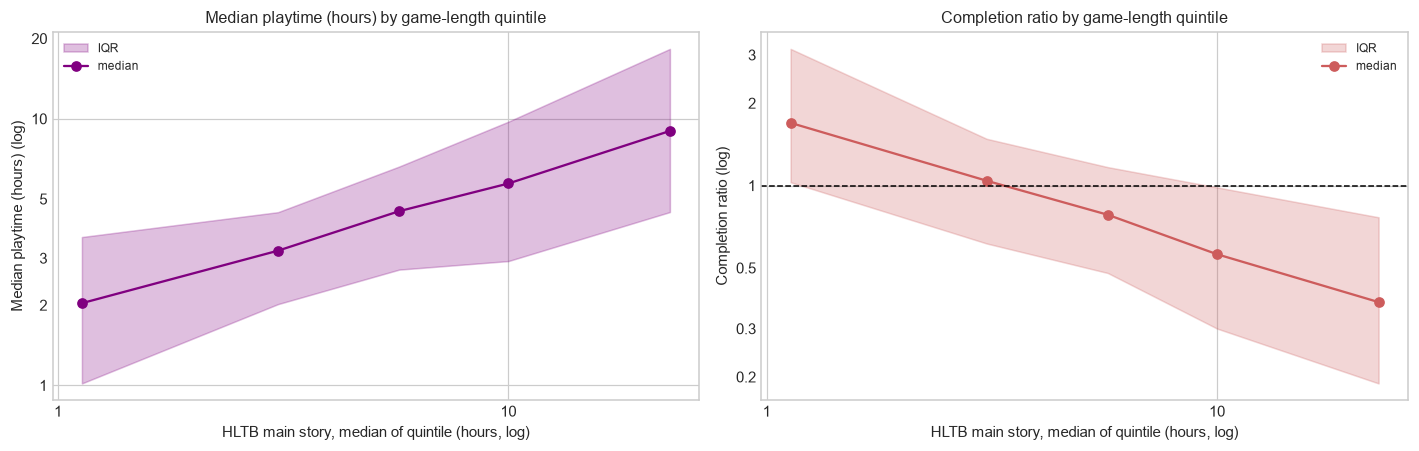

,games,spearman_playtime_vs_length,spearman_ratio_vs_length,loglog_slope,slope_ci_low,slope_ci_high
sample,,,,,,
usable ratio,3605,0.510,-0.508,0.511,0.479,0.542
completion-model sample,2409,0.558,-0.548,0.518,0.485,0.552


In [19]:
from scipy import stats

usable = df[df["completion_ratio"] > 0]
model_like = usable[(usable["steam_review_count"] >= 50) & (usable["hltb_main_story_polled"] >= 5)]
quintile = pd.qcut(usable["hltb_main_story"], 5)
by_length = usable.groupby(quintile, observed=True).agg(
    games=("steam_appid", "size"), median_main_story=("hltb_main_story", "median"),
    median_playtime=("steam_playtime_hours", "median"), median_ratio=("completion_ratio", "median"))
by_length.index = by_length.index.astype(str)
display(by_length.round(2))

rows = []
for name, frame in [("usable ratio", usable), ("completion-model sample", model_like)]:
    fit = stats.linregress(np.log(frame["hltb_main_story"]), np.log(frame["steam_playtime_hours"]))
    rows.append({"sample": name, "games": len(frame),
                 "spearman_playtime_vs_length": frame["steam_playtime_hours"].corr(frame["hltb_main_story"], method="spearman"),
                 "spearman_ratio_vs_length": frame["completion_ratio"].corr(frame["hltb_main_story"], method="spearman"),
                 "loglog_slope": fit.slope, "slope_ci_low": fit.slope - 1.96 * fit.stderr, "slope_ci_high": fit.slope + 1.96 * fit.stderr})
length_dependence = pd.DataFrame(rows).set_index("sample")
length_dependence.to_csv(config.TABLES / "01_length_dependence.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, label, colour in [(axes[0], "steam_playtime_hours", "Median playtime (hours)", "purple"),
                               (axes[1], "completion_ratio", "Completion ratio", "indianred")]:
    q = usable.groupby(quintile, observed=True)[col].quantile([0.25, 0.5, 0.75]).unstack()
    x = by_length["median_main_story"].to_numpy()
    ax.fill_between(x, q[0.25], q[0.75], alpha=0.25, color=colour, label="IQR")
    ax.plot(x, q[0.5], marker="o", color=colour, label="median")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.xaxis.set_major_formatter(READABLE); ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.yaxis.set_major_formatter(READABLE); ax.yaxis.set_minor_locator(mticker.LogLocator(subs=[2, 3, 5])); ax.yaxis.set_minor_formatter(READABLE)
    ax.set_xlabel("HLTB main story, median of quintile (hours, log)"); ax.set_ylabel(f"{label} (log)")
    ax.set_title(f"{label} by game-length quintile"); ax.legend(fontsize=8)
axes[1].axhline(1, color="black", linestyle="--", linewidth=1)
plt.tight_layout()
save_fig(fig, "01_q3_length_dependence")
plt.show()
length_dependence.round(3)

### Interpretation: Game length and the completion ratio
**Author**: 
<!-- Say how median playtime changes with game length and how the completion ratio changes with it, using the quintile table, the Spearman correlations and the log-log slope with its interval. Compare the slope with the two reference points (1 and 0). Say whether dividing by main-story hours removes the dependence on length, leaves it, or reverses it, and how much of the pattern could come from dividing by the same quantity on the x axis. State what this means for comparing short and long games on the ratio, and whether game length should be controlled for in AQ2. -->

*Written by AI Assistant*: whether a completion ratio exists at all, and how noisy it is when it does, depends on the evidence behind each side of it. The numerator rests on Steam's audience, for which review count stands in, and the denominator on the number of HowLongToBeat reports. The spread of the log ratio is used because, as the log-axis panels above show, the log scale is where the ratio is roughly symmetric.

In [20]:
# Zero ratios and noise, against the evidence behind each side of the ratio
ratio_frame = df.copy()
ratio_frame["ratio_is_zero"] = ratio_frame["completion_ratio"].eq(0)
ratio_nonzero = ratio_frame[~ratio_frame["ratio_is_zero"]].copy()
ratio_nonzero["log_ratio"] = np.log(ratio_nonzero["completion_ratio"])

review_bins = [-1, 0, 10, 50, 200, 1000, 5000, np.inf]
review_labels = ["0", "1-10", "11-50", "51-200", "201-1k", "1k-5k", "5k+"]
for frame in (ratio_frame, ratio_nonzero):
    frame["review_band"] = pd.cut(frame["steam_review_count"], bins=review_bins, labels=review_labels)

by_reviews = ratio_frame.groupby("review_band", observed=True).agg(
    games=("ratio_is_zero", "size"),
    pct_ratio_zero=("ratio_is_zero", lambda s: s.mean() * 100),
)
by_reviews["sd_log_ratio"] = ratio_nonzero.groupby("review_band", observed=True)["log_ratio"].std()
by_reviews["median_ratio"] = ratio_nonzero.groupby("review_band", observed=True)["completion_ratio"].median()
print("Numerator side, by Steam review count")
print(by_reviews.round(2).to_string())

poll_bins = [0, 1, 4, 10, 50, np.inf]
poll_labels = ["1", "2-4", "5-10", "11-50", "50+"]
ratio_nonzero["poll_band"] = pd.cut(ratio_nonzero["hltb_main_story_polled"], bins=poll_bins, labels=poll_labels)
by_polls = ratio_nonzero.groupby("poll_band", observed=True)["log_ratio"].agg(games="size", sd_log_ratio="std")
print("\nDenominator side, by HowLongToBeat main-story poll count (non-zero ratios only)")
print(by_polls.round(2).to_string())

for cut in (50, 200, 1000):
    sub = ratio_frame[ratio_frame["steam_review_count"] >= cut]
    print(f"\nat >= {cut:>4} reviews: {len(sub):,} games, "
          f"{sub['ratio_is_zero'].mean() * 100:.1f}% zero, {int((~sub['ratio_is_zero']).sum()):,} usable ratios", end="")
print()

print("\nSpearman correlation with the log ratio, non-zero ratios only:")
for col in ["steam_review_count", "steam_positive_rate"]:
    print(f"  {col}: {ratio_nonzero['log_ratio'].corr(ratio_nonzero[col], method='spearman'):.3f}")
print(f"  for comparison, ratio against review count with zeros included: "
      f"{ratio_frame['completion_ratio'].corr(ratio_frame['steam_review_count'], method='spearman'):.3f}")

Numerator side, by Steam review count
             games  pct_ratio_zero  sd_log_ratio  median_ratio
review_band                                                   
0               15           66.67          1.08          1.52
1-10           134           99.25           NaN          0.02
11-50          665           89.02          2.09          0.74
51-200        1267           54.30          1.76          0.80
201-1k        1517           14.77          1.27          1.00
1k-5k          971            1.85          1.04          0.79
5k+            712            1.54          0.81          0.64

Denominator side, by HowLongToBeat main-story poll count (non-zero ratios only)
           games  sd_log_ratio
poll_band                     
1            475          1.69
2-4          715          1.46
5-10         633          1.38
11-50        927          1.13
50+          855          0.79

at >=   50 reviews: 4,478 games, 21.2% zero, 3,529 usable ratios
at >=  200 reviews: 3,204 games

**Author**: [Insert Name]  
<!-- Interpret how the share of zero ratios and the spread of the log ratio change with Steam review count and with HowLongToBeat poll count. Cover what this implies for a minimum review threshold, what that threshold costs in games, whether review count and poll count should weight the ratio in AQ2, and why the correlation with review count changes so much once the zeros are removed. -->
With more data points, the sd of the ratio decreases. The more important observation is that the perecntage of zero completion ratio from 0-200 reviews hovers around 54-99%, while at 200+ it is only 7.9%.

In [21]:
def extremes(frame, col, n=5):
    sub = frame[frame[col].notna()]
    out = pd.concat([sub.nlargest(n, col), sub.nsmallest(n, col)])[
        ["steam_name", col, "steam_review_count", "steam_playtime_hours", "hltb_main_story"]].copy()
    out["steam_name"] = ascii_names(out["steam_name"])
    return out.round(2)

print("--- Highest and lowest completion ratio (positive only) ---")
print(extremes(df[df["completion_ratio"] > 0], "completion_ratio").to_string(index=False))
print("\n--- Highest and lowest positive rate, among games with at least 500 reviews ---")
print(extremes(df[df["steam_review_count"] >= 500], "steam_positive_rate").to_string(index=False))

--- Highest and lowest completion ratio (positive only) ---
                                             steam_name  completion_ratio  steam_review_count  steam_playtime_hours  hltb_main_story
             Letters From a Rainy Day -Oceans and Lace-            592.93                 897               5994.57            10.11
Lay a Beauty to Rest: The Darkness Peach Blossom Spring            305.31                6464               1471.62             4.82
                 Laid-Back Camp - Virtual - Lake Motosu            198.25                 372                116.97             0.59
                                                  GINKA            185.82                2604               1622.20             8.73
                                               Facehand            101.66                  93                185.02             1.82
                                    Open Sorcery: Sea++              0.00                  54                  0.02            33.00
         

## 4. What do the top games look like on each chosen target?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this section depends on section 3. It uses the three targets carried forward from the section 3 interpretation: review count, positive review rate, and completion ratio. A top game is one in the highest 1% on that target. Software rows from section 2 are excluded throughout. The positive rate and the completion ratio are only ranked among games with at least 500 reviews, because a rate built on a handful of reviews puts noise at the top rather than success, and because almost every game below that level has a completion ratio of zero (see the table at the end of section 3).

In [22]:
# Top games per chosen target from section 3
TARGETS = ["steam_review_count", "steam_positive_rate", "completion_ratio"]
assert set(TARGETS) <= set(candidates), "every chosen target must be one of the section 3 candidates"

TOP_SHARE = 0.01
MIN_REVIEWS_FOR_RATES = 500

eligible = df[~df["steam_is_software"]]
top_pools = {
    "steam_review_count": eligible,
    "steam_positive_rate": eligible[eligible["steam_review_count"] >= MIN_REVIEWS_FOR_RATES],
    "completion_ratio": eligible[(eligible["completion_ratio"] > 0)
                                 & (eligible["steam_review_count"] >= MIN_REVIEWS_FOR_RATES)],
}
assert list(top_pools) == TARGETS

top_sets, rows = {}, []
for metric, pool in top_pools.items():
    cut = pool[metric].quantile(1 - TOP_SHARE)
    top = pool[pool[metric] >= cut]
    top_sets[metric] = set(top["steam_appid"])
    rows.append({"target": metric, "ranked_among": len(pool), "cut_off": cut, "top_games": len(top)})
pd.DataFrame(rows).set_index("target").round(3)

,ranked_among,cut_off,top_games
target,,,
steam_review_count,5281,100285.600,53
steam_positive_rate,2271,0.987,23
completion_ratio,2208,10.514,23


In [23]:
show_cols = ["steam_name", "steam_review_count", "steam_positive_rate", "steam_metacritic_score",
             "steam_playtime_hours", "completion_ratio", "steam_price"]
for metric, pool in top_pools.items():
    t = pool.nlargest(10, metric)[show_cols].copy()
    t["steam_name"] = ascii_names(t["steam_name"])
    print(f"=== Top 10 by {metric} ===")
    print(t.round(2).to_string(index=False))
    print()

=== Top 10 by steam_review_count ===
                 steam_name  steam_review_count  steam_positive_rate  steam_metacritic_score  steam_playtime_hours  completion_ratio  steam_price
         Black Myth: Wukong             1150098                 0.97                       0                 46.87              1.23        59.99
             Cyberpunk 2077              844921                 0.84                      86                 53.55              2.06        20.99
   The Witcher 3: Wild Hunt              835349                 0.96                      93                 14.58              0.28         3.99
            Baldur's Gate 3              760662                 0.97                      96                 78.30              1.08        44.99
              Call of Duty?              714114                 0.59                       0                 11.95              1.74         0.00
                   Portal 2              433510                 0.99                   

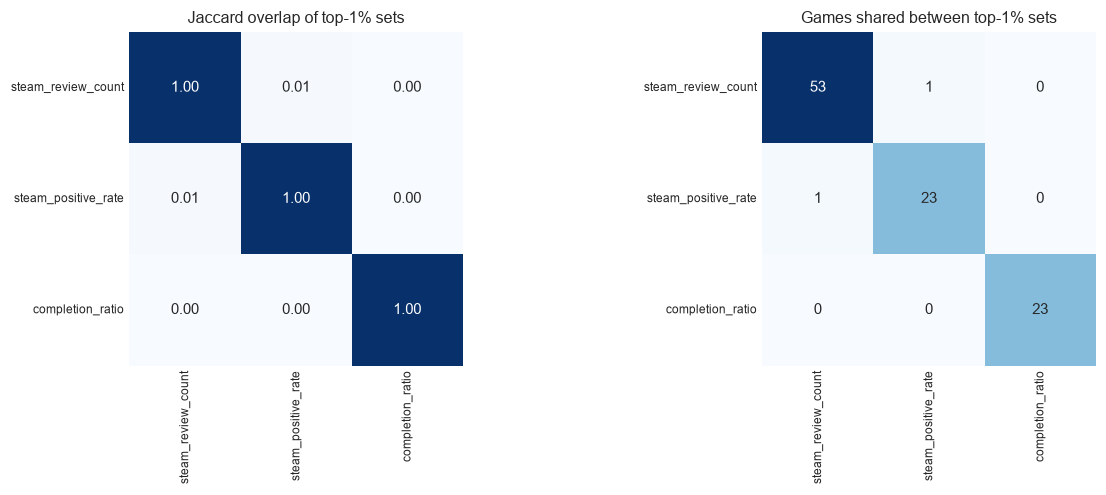

In [24]:
# Do the targets agree on which games are top? Jaccard overlap between the top sets:
# shared games divided by games in either set. 1 means identical sets, 0 means none shared.
names = list(top_sets)
jac = pd.DataFrame(index=names, columns=names, dtype=float)
shared = pd.DataFrame(index=names, columns=names, dtype=int)
for m1 in names:
    for m2 in names:
        union = top_sets[m1] | top_sets[m2]
        shared.loc[m1, m2] = len(top_sets[m1] & top_sets[m2])
        jac.loc[m1, m2] = shared.loc[m1, m2] / len(union) if union else np.nan

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(jac, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, cbar=False, ax=axes[0])
axes[0].set_title("Jaccard overlap of top-1% sets")
sns.heatmap(shared.astype(int), annot=True, fmt="d", cmap="Blues", square=True, cbar=False, ax=axes[1])
axes[1].set_title("Games shared between top-1% sets")
for ax in axes:
    ax.tick_params(labelsize=8)
plt.tight_layout()
save_fig(fig, "01_q4_top_set_overlap")
plt.show()

### Interpretation: Agreement between metrics on what a top game is
**Author**: [Insert Name]  
<!-- Use the top-10 lists and the overlap matrix to judge whether the candidate metrics agree on which games are successful. Cover which metrics pick out largely the same games, which pick out different ones, and what kinds of game each metric favours. Say what this means for AQ1: if the metrics disagree, choosing one is choosing a definition of success. -->


In [25]:
# Controllable variables: each top set against all eligible games as the reference
profile_vars = ["steam_price", "steam_achievements", "steam_language_count",
                "steam_dlc_count", "steam_years_since_release", "hltb_main_story"]
groups = {f"Top 1% {m}": eligible[eligible["steam_appid"].isin(top_sets[m])] for m in top_pools}
groups["All eligible games"] = eligible

profile = pd.DataFrame({
    g: {"games": len(frame), **{v: frame[v].median() for v in profile_vars}}
    for g, frame in groups.items()
}).T
print("Medians.")
profile.round(2)

Medians.


,games,steam_price,steam_achievements,steam_language_count,steam_dlc_count,steam_years_since_release,hltb_main_story
Top 1% steam_review_count,53.0,5.99,57.0,13.0,3.0,8.0,18.26
Top 1% steam_positive_rate,23.0,5.99,13.0,2.0,1.0,4.0,6.00
Top 1% completion_ratio,23.0,2.24,6.0,3.0,1.0,6.0,0.48
All eligible games,5281.0,4.39,19.0,4.0,0.0,6.0,4.24


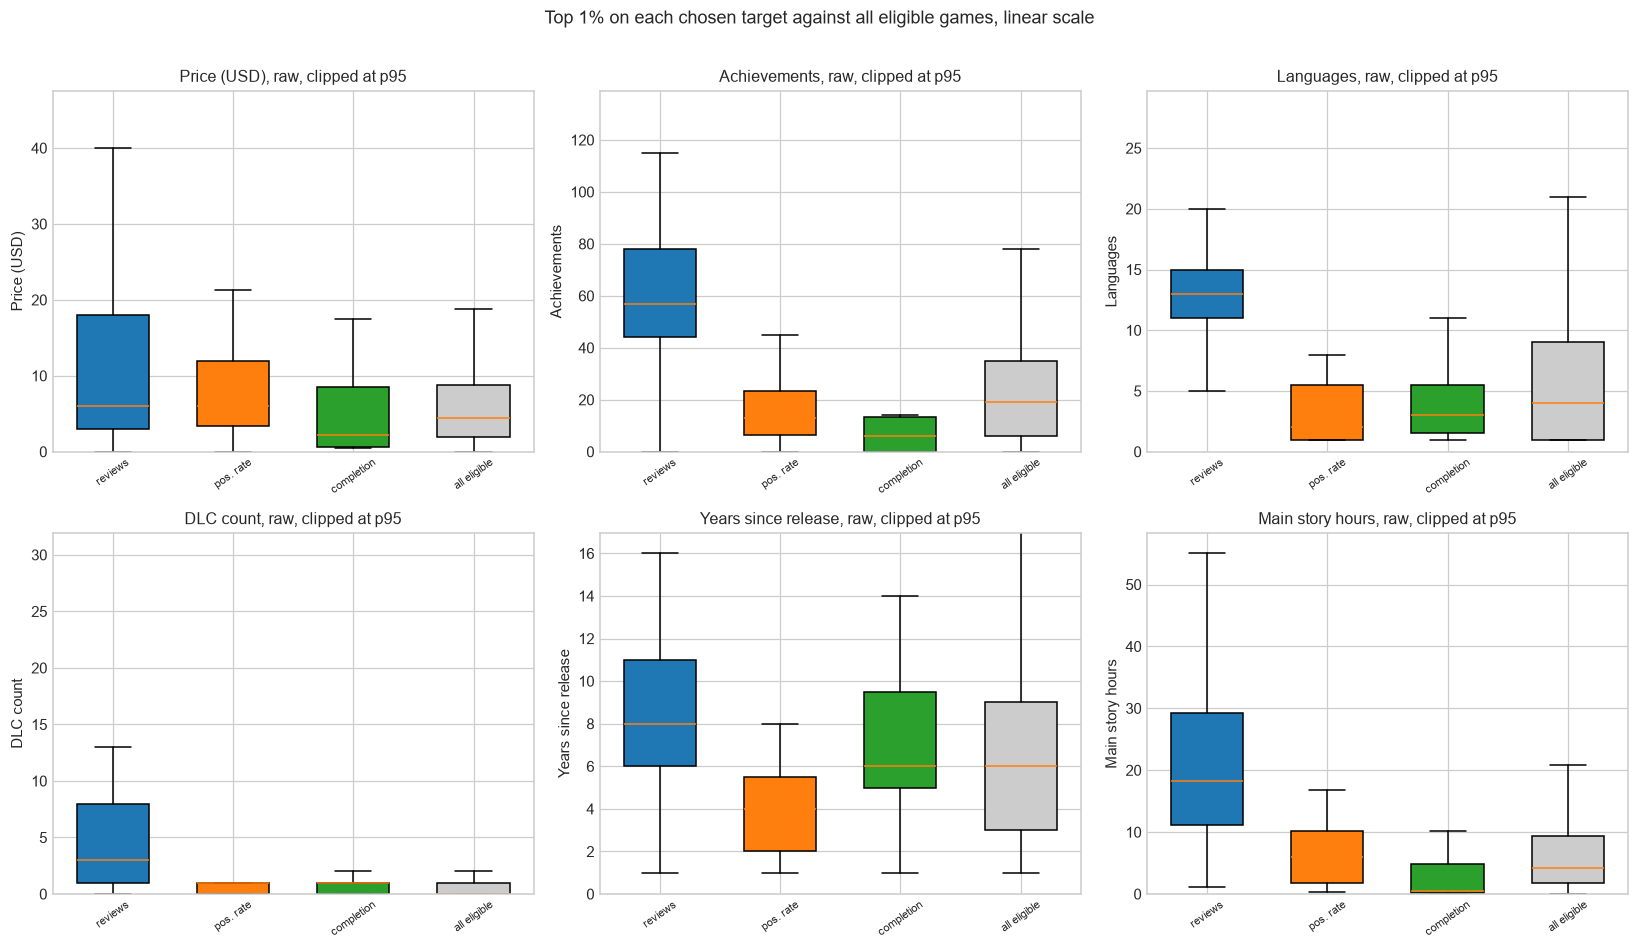

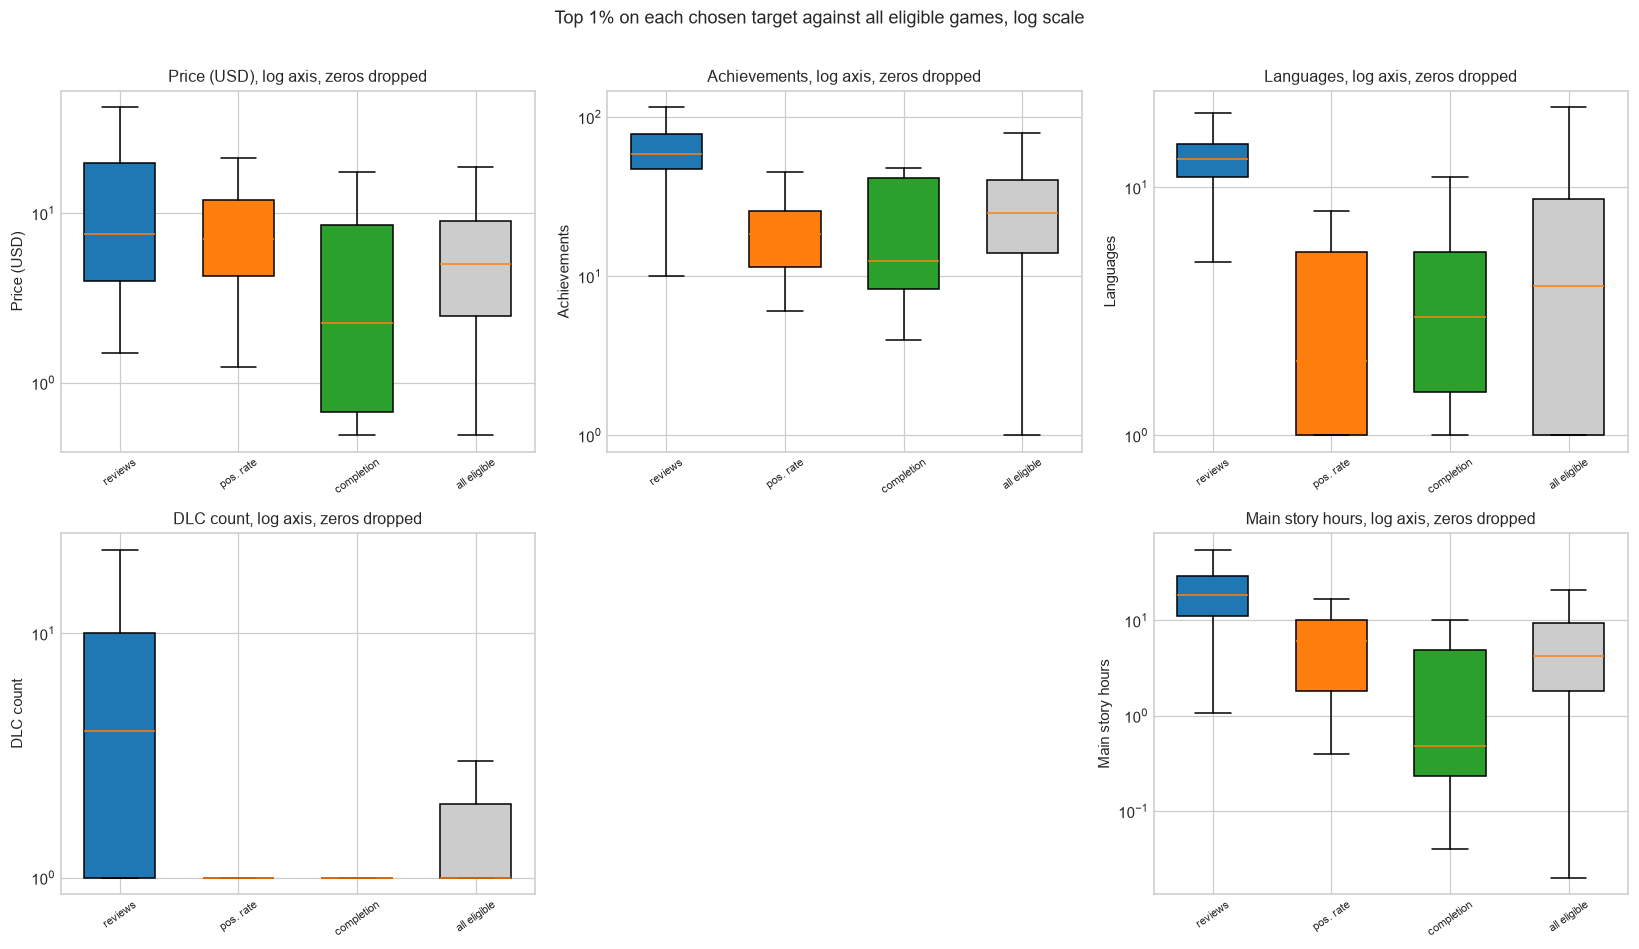

In [26]:
# The same comparison as distributions, raw first and then on a log axis
short = ["reviews", "pos. rate", "completion", "all eligible"]
compare = [
    ("steam_price", "Price (USD)", True),
    ("steam_achievements", "Achievements", True),
    ("steam_language_count", "Languages", True),
    ("steam_dlc_count", "DLC count", True),
    ("steam_years_since_release", "Years since release", False),
    ("hltb_main_story", "Main story hours", True),
]
colours = list(sns.color_palette("tab10", len(groups) - 1)) + [(0.8, 0.8, 0.8)]

def non_empty(values):
    """boxplot needs at least one value per group."""
    return values if len(values) else np.array([np.nan])

for scale in ["linear", "log"]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
    for ax, (col, label, loggable) in zip(axes.ravel(), compare):
        data = [frame[col].dropna() for frame in groups.values()]
        if scale == "log":
            if not loggable:
                ax.set_visible(False)
                continue
            data = [d[d > 0] for d in data]
        bp = ax.boxplot([non_empty(d.values) for d in data], patch_artist=True, showfliers=False, widths=0.6)
        for patch, colour in zip(bp["boxes"], colours):
            patch.set_facecolor(colour)
        ax.set_xticks(range(1, len(short) + 1))
        ax.set_xticklabels(short, rotation=35, fontsize=7.5)
        ax.set_ylabel(label)
        if scale == "log":
            ax.set_yscale("log")
            ax.set_title(f"{label}, log axis, zeros dropped")
        else:
            upper = max((d.quantile(0.95) for d in data if len(d)), default=0)
            if upper > 0:
                ax.set_ylim(0, upper * 1.1)
            ax.set_title(f"{label}, raw, clipped at p95")
    fig.suptitle(f"Top 1% on each chosen target against all eligible games, {scale} scale", y=1.01)
    plt.tight_layout()
    save_fig(fig, f"01_q4_top_by_metric_{scale}")
    plt.show()

### Interpretation: Top games against the rest of the population
**Author**: [Insert Name]  
<!-- Describe how the top games on each metric differ from all eligible games on the controllable variables. Cover which variables separate the top sets from the rest and which overlap too much to tell apart, and whether the pattern is consistent across metrics or specific to one. Say what this implies about predicting success from these variables. -->


## 5. How does game age affect each candidate metric?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: a success metric that grows with a game's age compares old games against new ones unfairly. The first two cells repeat the reception view: the unweighted mean treats every game equally, the pooled rate is total positives over total reviews, both with 95% error bars, and cohorts with fewer than 30 games are dropped. The third cell puts every candidate metric against age on the same footing: the median and interquartile range per release cohort, and the Spearman correlation with years since release. Zero playtime and zero completion ratio are SteamSpy non-estimates, not values, so they are left out of those two series.

In [27]:
# Reception against game age, with standard errors.
# SE of a mean is sd / sqrt(n). The pooled rate is total positives over total
# reviews, which weights each game by how many reviews it has.
rated = df[df["steam_review_count"] > 0]
age = rated.groupby("steam_years_since_release").agg(
    games=("steam_appid", "size"),
    mean_rate=("steam_positive_rate", "mean"),
    sd_rate=("steam_positive_rate", "std"),
    total_pos=("steam_positive", "sum"),
    total_rev=("steam_review_count", "sum"),
    median_reviews=("steam_review_count", "median"),
)
age["se_rate"] = age["sd_rate"] / np.sqrt(age["games"])
age["pooled_rate"] = age["total_pos"] / age["total_rev"]
age["pooled_se"] = np.sqrt(age["pooled_rate"] * (1 - age["pooled_rate"]) / age["total_rev"])
age = age[age["games"] >= 30]
age[["games", "mean_rate", "se_rate", "pooled_rate", "pooled_se", "median_reviews"]].round(4)

,games,mean_rate,se_rate,pooled_rate,pooled_se,median_reviews
steam_years_since_release,,,,,,
1,257,0.8886,0.0065,0.9069,0.0004,151.0
2,612,0.8521,0.0056,0.9166,0.0002,217.5
3,560,0.8495,0.0059,0.8729,0.0002,234.5
4,554,0.8342,0.0061,0.7808,0.0003,249.5
5,561,0.8379,0.0053,0.8948,0.0002,268.0
6,566,0.8449,0.0052,0.8988,0.0002,263.0
7,370,0.8238,0.0070,0.8759,0.0003,372.0
8,402,0.8266,0.0068,0.8825,0.0002,420.0
9,396,0.8074,0.0068,0.8715,0.0002,359.5


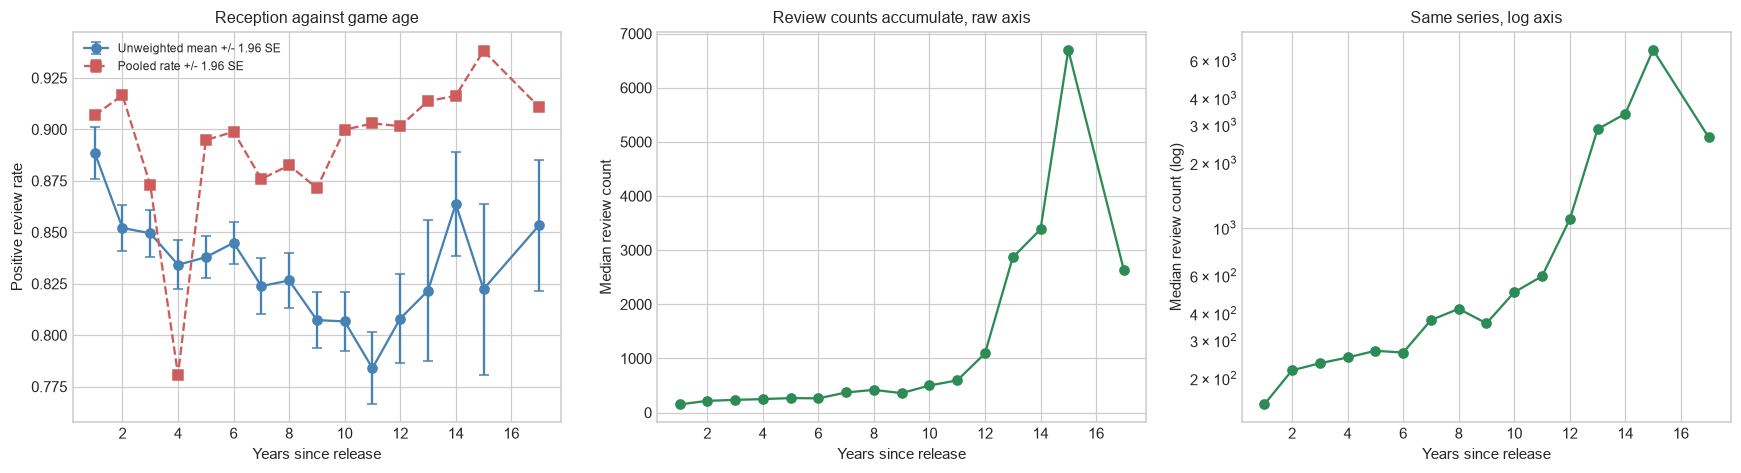

Error bars are narrow where a cohort has many games, so overlapping bars
matter more than the shape of the line.


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

axes[0].errorbar(age.index, age["mean_rate"], yerr=1.96 * age["se_rate"], fmt="o-",
                 capsize=3, color="steelblue", label="Unweighted mean +/- 1.96 SE")
axes[0].errorbar(age.index, age["pooled_rate"], yerr=1.96 * age["pooled_se"], fmt="s--",
                 capsize=3, color="indianred", label="Pooled rate +/- 1.96 SE")
axes[0].set_xlabel("Years since release"); axes[0].set_ylabel("Positive review rate")
axes[0].set_title("Reception against game age")
axes[0].legend(fontsize=8)

axes[1].plot(age.index, age["median_reviews"], marker="o", color="seagreen")
axes[1].set_xlabel("Years since release"); axes[1].set_ylabel("Median review count")
axes[1].set_title("Review counts accumulate, raw axis")

axes[2].plot(age.index, age["median_reviews"], marker="o", color="seagreen")
axes[2].set_yscale("log")
axes[2].set_xlabel("Years since release"); axes[2].set_ylabel("Median review count (log)")
axes[2].set_title("Same series, log axis")

plt.tight_layout()
save_fig(fig, "01_q5_age_and_reception")
plt.show()
print("Error bars are narrow where a cohort has many games, so overlapping bars")
print("matter more than the shape of the line.")

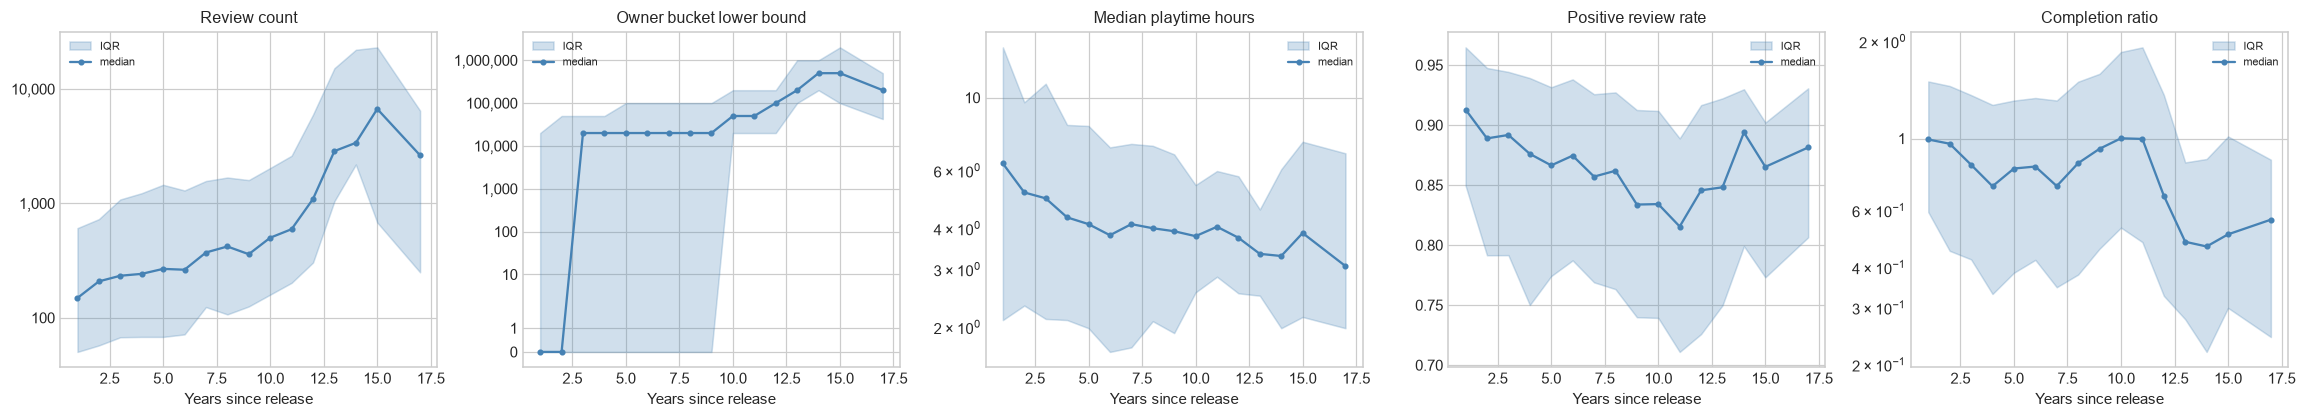

,games,spearman_with_age
metric,,
Review count,5208,0.231
Owner bucket lower bound,5208,0.299
Median playtime hours,3537,-0.107
Positive review rate,5193,-0.171
Completion ratio,3537,-0.013


In [29]:
# Every candidate metric against game age, on the same footing
age_metrics = {
    "Review count": (df["steam_review_count"].astype(float), "symlog"),
    "Owner bucket lower bound": (df["steam_owners_lower"].astype(float), "symlog"),
    "Median playtime hours": (df["steam_playtime_hours"].where(df["steam_playtime_hours"] > 0), "log"),
    "Positive review rate": (df["steam_positive_rate"], "linear"),
    "Completion ratio": (df["completion_ratio"].where(df["completion_ratio"] > 0), "log"),
}
cohort = df["steam_years_since_release"]
big_cohort = cohort.map(cohort.value_counts()) >= 30

fig, axes = plt.subplots(1, len(age_metrics), figsize=(21, 3.9))
age_rows = []
for ax, (label, (s, scale)) in zip(axes, age_metrics.items()):
    frame = pd.DataFrame({"age": cohort, "value": s})[big_cohort].dropna()
    q = frame.groupby("age")["value"].quantile([0.25, 0.5, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.25, color="steelblue", label="IQR")
    ax.plot(q.index, q[0.5], marker="o", markersize=3, color="steelblue", label="median")
    ax.set_yscale(scale)
    if scale != "linear":
        ax.yaxis.set_major_formatter(READABLE)
    ax.set_xlabel("Years since release")
    ax.set_title(label)
    ax.legend(fontsize=7)
    age_rows.append({"metric": label, "games": len(frame),
                     "spearman_with_age": round(frame["value"].corr(frame["age"], method="spearman"), 3)})
plt.tight_layout()
save_fig(fig, "01_q5_metrics_against_age")
plt.show()
pd.DataFrame(age_rows).set_index("metric")

### Interpretation: Game age and the candidate metrics
**Author**: [Insert Name]
<!-- Interpret the reception curves and the all-metrics panel. Cover whether reception genuinely varies with age or whether the differences sit inside the error bars, why the unweighted and pooled curves may diverge, which candidate metrics accumulate with age and which stay flat, what that means for comparing old and new games on each metric, how much of any age pattern could be survivorship among older games, and whether age needs to be controlled for in the AQ2 models. -->


## 6. How do the variables correlate?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: Spearman rather than Pearson, since these variables are skewed and the relationships are not expected to be linear. Spearman works on ranks, so it is unaffected by whether a variable is logged.

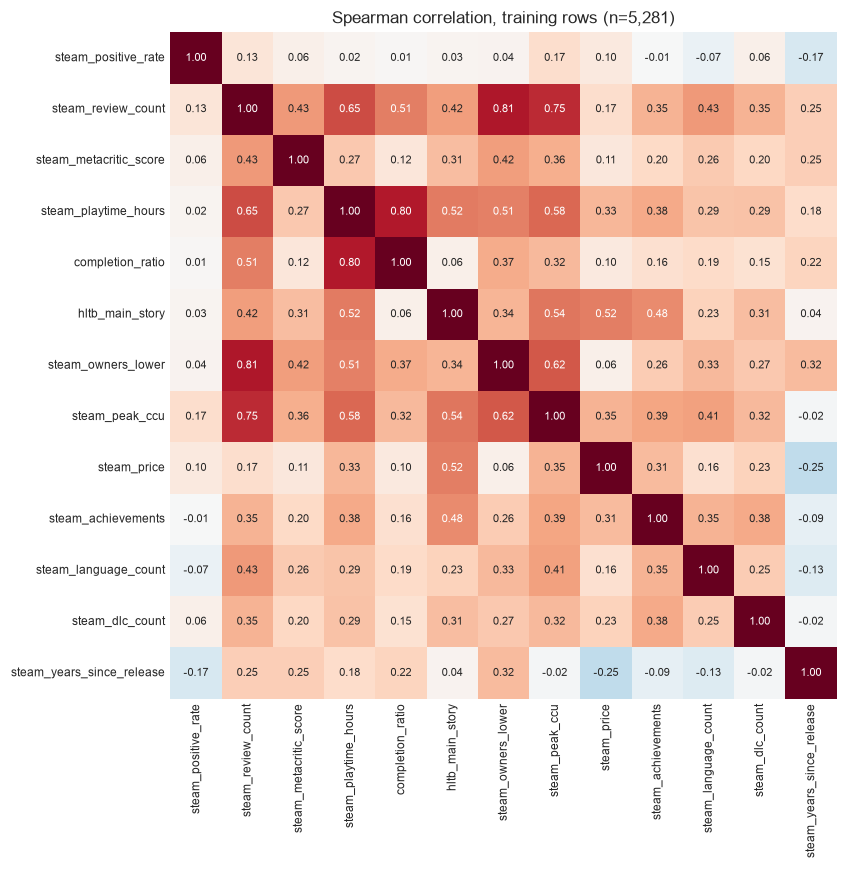

In [30]:
# Spearman rather than Pearson: these variables are skewed and the
# relationships are not expected to be linear.
num = ["steam_positive_rate", "steam_review_count", "steam_metacritic_score", "steam_playtime_hours",
       "completion_ratio", "hltb_main_story", "steam_owners_lower", "steam_peak_ccu", "steam_price",
       "steam_achievements", "steam_language_count", "steam_dlc_count", "steam_years_since_release"]

fig, ax = plt.subplots(figsize=(10, 8))
corr = df[num].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar=False, annot_kws={"size": 7}, ax=ax)
ax.set_title(f"Spearman correlation, training rows (n={len(df):,})", fontsize=11)
ax.tick_params(labelsize=8)
plt.tight_layout()
save_fig(fig, "01_q6_spearman_correlation")
plt.show()

In [31]:
targets = ["steam_positive_rate", "steam_review_count", "steam_metacritic_score",
           "steam_playtime_hours", "completion_ratio", "steam_owners_lower"]
print("Spearman correlation among candidate targets:")
print(df[targets].corr(method="spearman").round(3).to_string())

Spearman correlation among candidate targets:
                        steam_positive_rate  steam_review_count  steam_metacritic_score  steam_playtime_hours  completion_ratio  steam_owners_lower
steam_positive_rate                   1.000               0.132                   0.058                 0.025             0.015               0.037
steam_review_count                    0.132               1.000                   0.435                 0.649             0.511               0.806
steam_metacritic_score                0.058               0.435                   1.000                 0.271             0.121               0.420
steam_playtime_hours                  0.025               0.649                   0.271                 1.000             0.802               0.507
completion_ratio                      0.015               0.511                   0.121                 0.802             1.000               0.371
steam_owners_lower                    0.037               0.806   

### Interpretation: Correlation structure
**Author**: [Insert Name]  
<!-- Interpret the correlation structure. Cover which predictors move together closely enough to cause collinearity in a regression, how strongly the candidate targets agree with one another, whether the completion ratio carries information the review-based measures do not, and which relationships are strong enough to be worth modelling. -->


## 7. How much evidence sits behind each estimate?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the choice of metric in AQ1 depends on how reliably each candidate is measured, not only on how it is distributed. The Wilson interval is used rather than the normal approximation, which misbehaves for proportions near 0 and 1 and at small sample sizes.

In [32]:
bins = [-1, 0, 10, 50, 200, 1000, 5000, 20000, np.inf]
labels = ["0", "1-10", "11-50", "51-200", "201-1k", "1k-5k", "5k-20k", "20k+"]
df["steam_review_bucket"] = pd.cut(df["steam_review_count"], bins=bins, labels=labels)

z = 1.96
rated = df[df["steam_review_count"] > 0].copy()
n, p = rated["steam_review_count"], rated["steam_positive_rate"]
half = (z / (1 + z**2 / n)) * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
rated["wilson_width"] = 2 * half

by_bucket = rated.groupby("steam_review_bucket", observed=True).agg(
    games=("steam_appid", "size"),
    median_reviews=("steam_review_count", "median"),
    mean_positive_rate=("steam_positive_rate", "mean"),
    median_ci_width=("wilson_width", "median"),
)
print("Precision of the positive rate by review count:")
print(by_bucket.round(3).to_string())

print("\nEvidence behind the HowLongToBeat main-story time:")
print(df["hltb_main_story_polled"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_string())
print(f"games whose hltb_main_story rests on fewer than 5 reports: "
      f"{(df['hltb_main_story_polled'] < 5).sum():,} "
      f"({(df['hltb_main_story_polled'] < 5).mean() * 100:.1f}%)")

Precision of the positive rate by review count:
                     games  median_reviews  mean_positive_rate  median_ci_width
steam_review_bucket                                                            
1-10                   134             6.0               0.774            0.545
11-50                  665            30.0               0.809            0.257
51-200                1267           107.0               0.814            0.133
201-1k                1517           409.0               0.834            0.064
1k-5k                  971          2089.0               0.853            0.027
5k-20k                 446          8865.0               0.871            0.012
20k+                   266         44089.0               0.895            0.005

Evidence behind the HowLongToBeat main-story time:
count    5281.0
mean       77.0
std       294.0
min         1.0
10%         1.0
25%         2.0
50%         5.0
75%        22.0
90%       127.0
max      5598.0
games whose hltb_mai

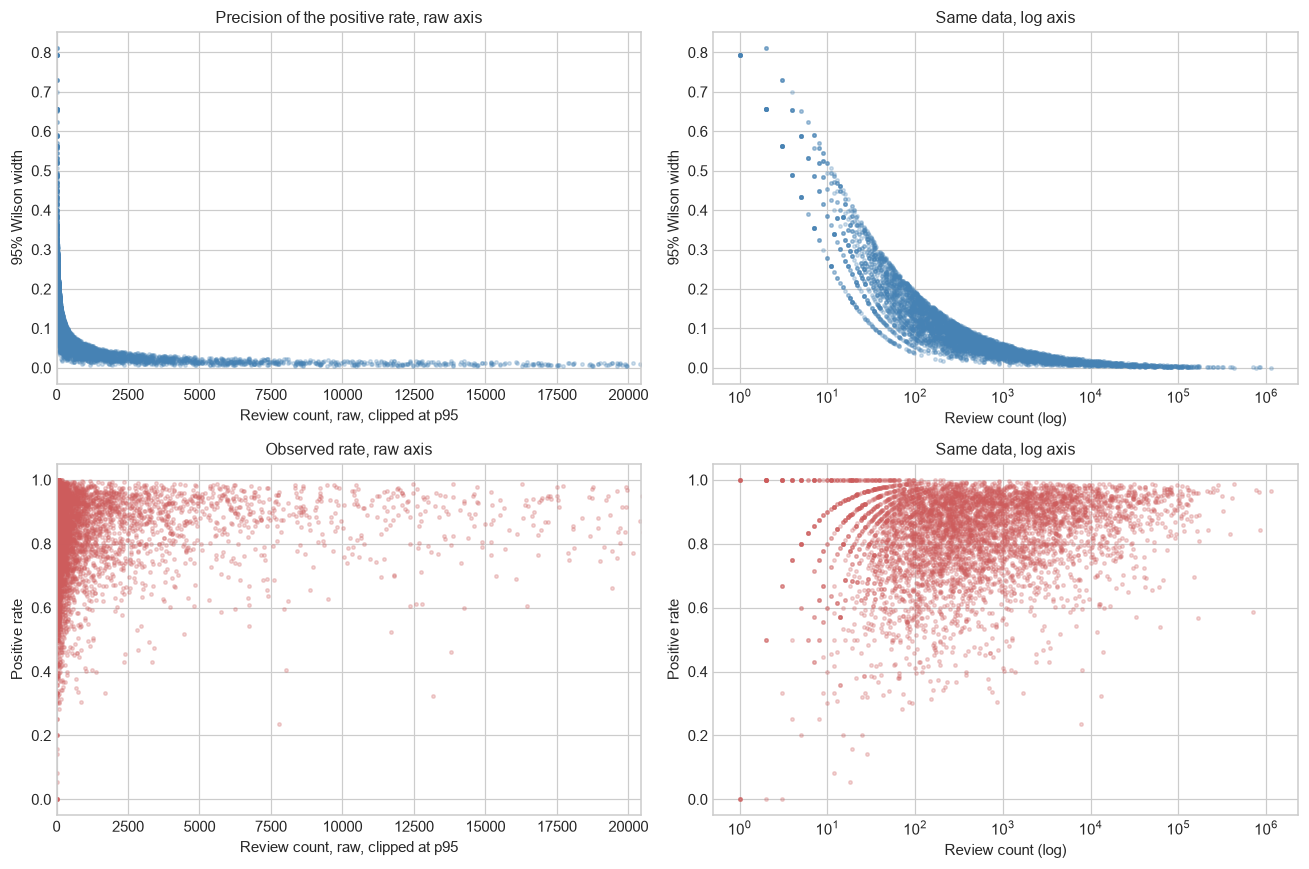

In [33]:
s = rated.sample(min(8000, len(rated)), random_state=config.SEED)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(s["steam_review_count"], s["wilson_width"], s=5, alpha=0.25, color="steelblue")
axes[0, 0].set_xlim(0, s["steam_review_count"].quantile(0.95))
axes[0, 0].set_xlabel("Review count, raw, clipped at p95"); axes[0, 0].set_ylabel("95% Wilson width")
axes[0, 0].set_title("Precision of the positive rate, raw axis")

axes[0, 1].scatter(s["steam_review_count"], s["wilson_width"], s=5, alpha=0.25, color="steelblue")
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlabel("Review count (log)"); axes[0, 1].set_ylabel("95% Wilson width")
axes[0, 1].set_title("Same data, log axis")

axes[1, 0].scatter(s["steam_review_count"], s["steam_positive_rate"], s=5, alpha=0.25, color="indianred")
axes[1, 0].set_xlim(0, s["steam_review_count"].quantile(0.95))
axes[1, 0].set_xlabel("Review count, raw, clipped at p95"); axes[1, 0].set_ylabel("Positive rate")
axes[1, 0].set_title("Observed rate, raw axis")

axes[1, 1].scatter(s["steam_review_count"], s["steam_positive_rate"], s=5, alpha=0.25, color="indianred")
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlabel("Review count (log)"); axes[1, 1].set_ylabel("Positive rate")
axes[1, 1].set_title("Same data, log axis")

plt.tight_layout()
save_fig(fig, "01_q7_evidence_raw_vs_log")
plt.show()

### Interpretation: Evidence behind the estimates
**Author**: [Insert Name]  
<!-- Interpret how much the precision of each measure varies across games. Cover how wide the interval on the positive rate is for a game at the low end against the high end, how many games rest on very few HowLongToBeat reports, and whether the right response is a minimum-evidence threshold, partial pooling, or carrying the uncertainty through the model. -->


## 8. How do the candidate metrics compare side by side?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: one row per candidate metric, pulling together sections 3, 5 and 7. `usable` counts games where the metric carries a value: for median playtime and the completion ratio a zero is a SteamSpy non-estimate, so zeros are not counted as usable. `spearman_with_age` is the rank correlation with years since release, and `spearman_with_reviews` the rank correlation with review count, a stand-in for audience size, and `spearman_with_main_story` the rank correlation with HowLongToBeat main-story hours, a measure of game length. Both are computed on usable values only. `skew_log` is the skew of the log of the positive values, so it reads how far each metric is from symmetric after a log transform.

In [34]:
zero_is_missing = {"steam_playtime_hours", "completion_ratio"}
summary_metrics = {
    "steam_review_count": df["steam_review_count"].astype(float),
    "steam_owners_lower": df["steam_owners_lower"].astype(float),
    "steam_playtime_hours": df["steam_playtime_hours"],
    "steam_positive_rate": df["steam_positive_rate"],
    "steam_metacritic_score": df["steam_metacritic_score"].where(df["steam_metacritic_score"] > 0).astype(float),
    "completion_ratio": df["completion_ratio"],
}
rows = []
for name, s in summary_metrics.items():
    usable = s.notna() & ((s > 0) if name in zero_is_missing else True)
    u = s[usable]
    positive = u[u > 0]
    rows.append({
        "metric": name,
        "usable": int(usable.sum()),
        "pct_usable": round(usable.mean() * 100, 1),
        "pct_zero_of_defined": round(float((s.dropna() == 0).mean() * 100), 1),
        "spearman_with_age": round(u.corr(df.loc[usable, "steam_years_since_release"], method="spearman"), 3),
        "spearman_with_reviews": (np.nan if name == "steam_review_count" else
                                  round(u.corr(df.loc[usable, "steam_review_count"], method="spearman"), 3)),
        "spearman_with_main_story": round(u.corr(df.loc[usable, "hltb_main_story"], method="spearman"), 3),
        "skew_raw": round(float(u.skew()), 2),
        "skew_log": round(float(np.log(positive).skew()), 2) if len(positive) > 2 else np.nan,
    })
metric_summary = pd.DataFrame(rows).set_index("metric")
config.TABLES.mkdir(parents=True, exist_ok=True)
metric_summary.to_csv(config.TABLES / "01_metric_summary.csv")
metric_summary

,usable,pct_usable,pct_zero_of_defined,spearman_with_age,spearman_with_reviews,spearman_with_main_story,skew_raw,skew_log
metric,,,,,,,,
steam_review_count,5281,100.0,0.3,0.249,NaN,0.415,19.41,0.37
steam_owners_lower,5281,100.0,38.4,0.318,0.806,0.338,26.56,0.84
steam_playtime_hours,3605,68.3,31.7,-0.118,0.271,0.510,49.13,-0.70
steam_positive_rate,5266,99.7,0.1,-0.167,0.132,0.026,-1.56,-2.99
steam_metacritic_score,1095,20.7,0.0,-0.106,0.414,0.279,-0.72,-1.22
completion_ratio,3605,68.3,31.7,-0.044,-0.107,-0.508,36.06,-0.74


### Interpretation: Choosing a target variable
**Author**: Lee Sin Yang 

> **AI note, out of date (scope is now story-driven games matched to HowLongToBeat):** this answer now sits after section 8, the side-by-side metric table. Review it against that table, and note that AQ2 now models the completion ratio only. Delete this note once revised.

<!-- This is the answer to AQ1. Evaluate each candidate target against what a studio needs to know and what the data can support: how many games it is defined for, how it is distributed on both the raw and log views, what its outliers are and whether they are real, and whether it measures success or merely exposure. Address the completion ratio directly, including its zero inflation and what the two components show when plotted separately. State which target or targets you carry into AQ2 and AQ3, and why you set the others aside. -->
Of the various metrics, we can identify 2 main types of "popularity" - how widespread it is (number of reviews, owners) and satisfaction (rating, completion ratio). Of these two categories, we move ahead with the number of reviews, positive review rating, and completion ratio as these have the most number of data points. For completion ratio, while it might not have the most data points, it might paint a truer picture of game reception than review rating as steam reviews can be comedic (e.g. rating negative while having 1000 hours played), and only users with strong opinions will leave a review. We believe that completion ratio, a numbers-backed approach, reveals more about true user behaviour. We keep positive review rate as a backup metric, but completion ratio is our main metric.

Number of reviews materially affects the completion ratio, with games over 200 reviews having only 7.9% 0 completion ratio while <10 reviews having 99.3%. Thus, we will filter by reviews for our modelling as these zero values are essentially data points that have not discovered their true value. While these would introduce some bias, a model trained with the zero ratios included (due to an inability to measure playtime) would introduce much more noise.


## Save for stage 02
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this stage adds derived columns and filters no rows, so the count out matches the count in. The cleaning decisions raised above belong to stage 02.

In [35]:
df.to_parquet(config.INTERIM / "01_eda.parquet", index=False)
print(f"rows in : {len(train):,}")
print(f"rows out: {len(df):,}  (no rows filtered in this stage)")
print(f"columns : {train.shape[1]} in, {df.shape[1]} out")
print(f"figures : {len(list(config.FIGURES.glob('01_*.png')))} written to outputs/figures")

rows in : 5,281
rows out: 5,281  (no rows filtered in this stage)
columns : 74 in, 85 out
figures : 15 written to outputs/figures
